<a href="https://colab.research.google.com/github/LakinduSachin/CR-CM-Coursework/blob/main/test_02_CR_%26_CM_Course_work.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# Task 1: Data Preparation and Feature Engineering
# 1.1 Ticker Selection and Data Acquisition

# Import the libraries needed for the analysis
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

# Record the date when the ticker list is retrieved
retrieval_date = pd.Timestamp.today().strftime('%Y-%m-%d')

print("Ticker retrieval date:", retrieval_date)


Ticker retrieval date: 2026-11-17


In [ ]:

# Extract the S&P 500 company list from Wikipedia using pandas
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'

# Read the table containing the S&P 500 companies
tables = pd.read_html(
    url,
    storage_options={"User-Agent": "Mozilla/5.0"}
)

sp500_df = tables[0]

# Display the first five companies
print(sp500_df.head())

# Extract the ticker symbols
tickers = sp500_df['Symbol'].tolist()

# Replace dots with hyphens for Yahoo Finance
tickers = [t.replace('.', '-') for t in tickers]

# Check the total number of tickers extracted
print("Total tickers extracted:", len(tickers))


  Symbol             Security             GICS Sector  \
0    MMM                   3M             Industrials   
1    AOS          A. O. Smith             Industrials   
2    ABT  Abbott Laboratories             Health Care   
3   ABBV               AbbVie             Health Care   
4    ACN            Accenture  Information Technology   

                GICS Sub-Industry    Headquarters Location  Date added  \
0        Industrial Conglomerates    Saint Paul, Minnesota  1957-03-04   
1               Building Products     Milwaukee, Wisconsin  2017-07-26   
2           Health Care Equipment  North Chicago, Illinois  1957-03-04   
3                   Biotechnology  North Chicago, Illinois  2012-12-31   
4  IT Consulting & Other Services          Dublin, Ireland  2011-07-06   

       CIK      Founded  
0    66740         1902  
1    91142         1916  
2     1800         1888  
3  1551152  2013 (1888)  
4  1467373         1989  
Total tickers extracted: 503


In [ ]:

# Set the start and end dates according to the coursework
start = '2021-01-01'
end = '2025-01-01'

# The end date is exclusive
print("Start date:", start)
print("End date (exclusive):", end)


Start date: 2021-01-01
End date (exclusive): 2025-01-01


In [ ]:

# Test the Yahoo Finance download using five shares
sample_tickers = tickers[:5]

sample_data = yf.download(
    sample_tickers,
    start=start,
    end=end,
    auto_adjust=False,
    actions=True,
    progress=False
)

# Display the downloaded data
print(sample_data.head())

# Check the available data columns
print(sample_data.columns)


Price       Adj Close                                                \
Ticker           ABBV        ABT         ACN        AOS         MMM   
Date                                                                  
2021-01-04  84.219147  97.269714  232.029343  48.167679  117.366722   
2021-01-05  85.090019  98.473183  233.350281  48.480328  117.168648   
2021-01-06  84.354973  98.268166  235.901611  50.150841  118.950981   
2021-01-07  85.257797  99.222054  238.127319  50.767227  115.898499   
2021-01-08  85.705200  99.498405  238.995850  50.168705  113.781548   

Price            Close                                                 ...  \
Ticker            ABBV         ABT         ACN        AOS         MMM  ...   
Date                                                                   ...   
2021-01-04  105.410004  109.110001  256.459991  53.919998  143.704010  ...   
2021-01-05  106.500000  110.459999  257.920013  54.270000  143.461533  ...   
2021-01-06  105.580002  110.230003  260.7

In [ ]:

# Download the daily historical data for the S&P 500 shares
stock_data = yf.download(
    tickers,
    start=start,
    end=end,
    auto_adjust=False,
    actions=True,
    progress=False,
    threads=True
)

# Download the S&P 500 benchmark data
benchmark_data = yf.download(
    '^GSPC',
    start=start,
    end=end,
    auto_adjust=False,
    actions=True,
    progress=False
)

# Check the downloaded data
print("Stock data shape:", stock_data.shape)
print("Benchmark data shape:", benchmark_data.shape)

print(stock_data.head())
print(benchmark_data.head())


ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['SNDK', 'HONA', 'Q', 'FDXF', 'VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Stock data shape: (1005, 4014)
Benchmark data shape: (1005, 8)
Price        Adj Close                                                \
Ticker               A        AAPL       ABBV        ABNB        ABT   
Date                                                                   
2021-01-04  114.009125  125.537102  84.219147  139.149994  97.269714   
2021-01-05  114.941277  127.089241  85.090012  148.300003  98.473198   
2021-01-06  118.093231  122.811226  84.354965  142.770004  98.268166   
2021-01-07  121.235596  127.001915  85.257774  151.270004  99.222054   
2021-01-08  122.100441  128.098114  85.705215  149.770004  99.498398   

Price                                                                 ...  \
Ticker           ACGL         ACN        ADBE         ADI        ADM  ...   
Date                                                                  ...   
2021-01-04  33.186359  232.029327  485.339996  132.622650  42.507668  ...   
2021-01-05  33.319485  233.350235  485.690002  134.9

In [ ]:

# Save the ticker list and company information
sp500_df.to_csv('sp500_ticker_list.csv', index=False)

# Save the downloaded historical data
stock_data.to_csv('sp500_daily_data.csv')
benchmark_data.to_csv('sp500_benchmark_data.csv')

# Save information about the data source and dates
data_info = pd.DataFrame({
    'Source': ['Wikipedia', 'Yahoo Finance'],
    'Retrieval_Date': [retrieval_date, retrieval_date],
    'Start_Date': [start, start],
    'End_Date_Exclusive': [end, end]
})

data_info.to_csv('data_source_info.csv', index=False)

print("Data files saved successfully")


Data files saved successfully


In [ ]:

# 1.2 Data Validation and Alignment

# Check for duplicate dates in the datasets
print("Duplicate stock dates:", stock_data.index.duplicated().sum())
print("Duplicate benchmark dates:", benchmark_data.index.duplicated().sum())

# Check the first and last dates
print("Stock date range:", stock_data.index.min(), "to", stock_data.index.max())
print("Benchmark date range:", benchmark_data.index.min(), "to", benchmark_data.index.max())


Duplicate stock dates: 0
Duplicate benchmark dates: 0
Stock date range: 2021-01-04 00:00:00 to 2024-12-31 00:00:00
Benchmark date range: 2021-01-04 00:00:00 to 2024-12-31 00:00:00


In [ ]:

# Extract adjusted close, close and volume for validation
adj_close = stock_data['Adj Close']
close = stock_data['Close']
volume = stock_data['Volume']

# Extract the benchmark adjusted closing prices
benchmark_adj = benchmark_data['Adj Close']['^GSPC']

# Check the number of shares with available columns
print("Shares in dataset:", len(adj_close.columns))
print("Benchmark observations:", benchmark_adj.notna().sum())


Shares in dataset: 503
Benchmark observations: 1005


In [ ]:

# Count missing values for each share
missing_values = pd.DataFrame({
    'Missing_Adj_Close': adj_close.isna().sum(),
    'Missing_Close': close.isna().sum(),
    'Missing_Volume': volume.isna().sum(),
    'Available_Days': adj_close.notna().sum()
})

# Check when the available price history starts and ends
missing_values['First_Date'] = adj_close.apply(
    lambda x: x.first_valid_index()
)

missing_values['Last_Date'] = adj_close.apply(
    lambda x: x.last_valid_index()
)

# Display shares with the most missing values
print(missing_values.sort_values(
    'Missing_Adj_Close', ascending=False
).head(15))

# Check missing benchmark prices
print("Missing benchmark prices:", benchmark_adj.isna().sum())


        Missing_Adj_Close  Missing_Close  Missing_Volume  Available_Days  \
Ticker                                                                     
SNDK                 1005           1005            1005               0   
VYLR                 1005           1005            1005               0   
HONA                 1005           1005            1005               0   
Q                    1005           1005            1005               0   
FDXF                 1005           1005            1005               0   
GEV                   812            812             812             193   
SOLV                  811            811             811             194   
RDDT                  808            808             808             197   
VLTO                  692            692             692             313   
GEHC                  492            492             492             513   
CEG                   263            263             263             742   
HOOD        

In [ ]:

# Check nonpositive closing prices
invalid_adj_close = ((adj_close <= 0) & adj_close.notna()).sum()
invalid_close = ((close <= 0) & close.notna()).sum()

# Check negative and zero trading volumes separately
negative_volume = (volume < 0).sum()
zero_volume = (volume == 0).sum()

# Summarise validation results for each share
validation = pd.DataFrame({
    'Invalid_Adj_Close': invalid_adj_close,
    'Invalid_Close': invalid_close,
    'Negative_Volume': negative_volume,
    'Zero_Volume': zero_volume
})

print(validation.describe())
print("Shares with invalid adjusted prices:",
      (invalid_adj_close > 0).sum())
print("Shares with negative volume:",
      (negative_volume > 0).sum())


       Invalid_Adj_Close  Invalid_Close  Negative_Volume  Zero_Volume
count              503.0          503.0            503.0   503.000000
mean                 0.0            0.0              0.0     0.896620
std                  0.0            0.0              0.0    18.941124
min                  0.0            0.0              0.0     0.000000
25%                  0.0            0.0              0.0     0.000000
50%                  0.0            0.0              0.0     0.000000
75%                  0.0            0.0              0.0     0.000000
max                  0.0            0.0              0.0   424.000000
Shares with invalid adjusted prices: 0
Shares with negative volume: 0


In [ ]:

# Check stock splits and dividends in the downloaded data
splits = stock_data['Stock Splits']
dividends = stock_data['Dividends']

# Count the corporate actions recorded for each share
corporate_actions = pd.DataFrame({
    'Split_Days': (splits.fillna(0) != 0).sum(),
    'Dividend_Days': (dividends.fillna(0) != 0).sum()
})

# Display shares with the most recorded splits
print(corporate_actions.sort_values(
    'Split_Days', ascending=False
).head(15))


        Split_Days  Dividend_Days
Ticker                           
GE               3             16
APH              2             16
ANET             2              0
WRB              2             17
PANW             2              0
NVDA             2             16
CPRT             2              0
COO              1              6
BDX              1             16
MMM              1             16
O                1             47
ODFL             1             16
EXC              1             16
ETR              1             16
AVGO             1             16


In [ ]:

# Record the validation result for every requested ticker
exclusion_log = pd.DataFrame(index=tickers)
exclusion_log.index.name = 'Ticker'

# Record whether the share has downloaded price data
exclusion_log['Available_Days'] = (
    adj_close.notna().sum().reindex(tickers, fill_value=0)
)

# Identify shares without downloaded prices
exclusion_log['Status'] = 'Review'
exclusion_log.loc[
    exclusion_log['Available_Days'] == 0, 'Status'
] = 'No historical prices'

# Flag shares with invalid prices or negative volume
invalid_tickers = validation.index[
    (validation['Invalid_Adj_Close'] > 0) |
    (validation['Invalid_Close'] > 0) |
    (validation['Negative_Volume'] > 0)
]

exclusion_log.loc[
    exclusion_log.index.isin(invalid_tickers) &
    (exclusion_log['Available_Days'] > 0),
    'Status'
] = 'Invalid data - investigate'

# Save the initial log for further validation
exclusion_log.to_csv('stock_validation_log.csv')

print(exclusion_log['Status'].value_counts())
print(exclusion_log.head())


Status
Review                  498
No historical prices      5
Name: count, dtype: int64
        Available_Days  Status
Ticker                        
MMM               1005  Review
AOS               1005  Review
ABT               1005  Review
ABBV              1005  Review
ACN               1005  Review


In [ ]:

# Identify dates shared by stocks and the benchmark
common_dates = stock_data.index.intersection(
    benchmark_data.index
)

# Keep matching date labels without filling missing prices
aligned_adj_close = adj_close.loc[common_dates]
aligned_benchmark = benchmark_adj.loc[common_dates]

# Check the aligned date range
print("Common daily dates:", len(common_dates))
print("First common date:", common_dates.min())
print("Last common date:", common_dates.max())

# Check missing benchmark values after alignment
print("Missing benchmark values:",
      aligned_benchmark.isna().sum())


Common daily dates: 1005
First common date: 2021-01-04 00:00:00
Last common date: 2024-12-31 00:00:00
Missing benchmark values: 0


In [ ]:

# Save the validation and corporate action summaries
missing_values.to_csv('missing_values_summary.csv')
validation.to_csv('price_volume_validation.csv')
corporate_actions.to_csv('corporate_actions_summary.csv')

print("Validation results saved successfully")


Validation results saved successfully


In [ ]:

# 1.3.1 Mean Weekly Return

# Resample adjusted closing prices into Friday-ending weeks
weekly_prices = aligned_adj_close.resample('W-FRI').last()

# Resample benchmark adjusted closing prices
weekly_benchmark = aligned_benchmark.resample('W-FRI').last()

# Remove incomplete first and final calendar weeks
weekly_prices = weekly_prices.loc[
    '2021-01-08':'2024-12-27'
]

weekly_benchmark = weekly_benchmark.loc[
    '2021-01-08':'2024-12-27'
]

# Display weekly prices
print(weekly_prices.head())
print(weekly_benchmark.head())

print("Total weekly price observations:", len(weekly_prices))


Ticker               A        AAPL       ABBV        ABNB         ABT  \
Date                                                                    
2021-01-08  122.100441  128.098114  85.705215  149.770004   99.498398   
2021-01-15  121.283646  123.335052  89.334641  169.270004   99.621780   
2021-01-22  121.398964  134.907990  89.609459  181.869995  101.000183   
2021-01-29  115.479408  128.010803  82.835800  183.630005  110.622238   
2021-02-05  118.371925  132.865402  87.887756  195.309998  111.016083   

Ticker           ACGL         ACN        ADBE         ADI        ADM  ...  \
Date                                                                  ...   
2021-01-08  34.650742  238.995865  485.100006  142.359100  44.809063  ...   
2021-01-15  32.986668  230.271240  458.079987  143.276382  44.493698  ...   
2021-01-22  31.674431  231.287994  472.440002  141.305511  45.022167  ...   
2021-01-29  29.867723  219.622391  458.769989  133.812424  42.626991  ...   
2021-02-05  32.140369  230

In [ ]:

# Calculate weekly returns using adjusted closing prices
# Weekly Return = (Current Week Price / Previous Week Price) - 1

weekly_returns = weekly_prices.pct_change(fill_method=None)

# Calculate weekly benchmark returns using the same formula
benchmark_returns = weekly_benchmark.pct_change(fill_method=None)

# Display the calculated returns
print(weekly_returns.head())
print(benchmark_returns.head())


Ticker             A      AAPL      ABBV      ABNB       ABT      ACGL  \
Date                                                                     
2021-01-08       NaN       NaN       NaN       NaN       NaN       NaN   
2021-01-15 -0.006690 -0.037183  0.042348  0.130200  0.001240 -0.048024   
2021-01-22  0.000951  0.093833  0.003076  0.074437  0.013836 -0.039781   
2021-01-29 -0.048761 -0.051125 -0.075591  0.009677  0.095268 -0.057040   
2021-02-05  0.025048  0.037923  0.060988  0.063606  0.003560  0.076090   

Ticker           ACN      ADBE       ADI       ADM  ...        WY      WYNN  \
Date                                                ...                       
2021-01-08       NaN       NaN       NaN       NaN  ...       NaN       NaN   
2021-01-15 -0.036505 -0.055700  0.006443 -0.007038  ... -0.025764 -0.025681   
2021-01-22  0.004415  0.031348 -0.013756  0.011877  ...  0.021217  0.011484   
2021-01-29 -0.050438 -0.028935 -0.053028 -0.053200  ... -0.060825 -0.073709   
2021-02

In [ ]:

# Keep the same weekly labels for shares and benchmark
weekly_returns = weekly_returns.reindex(
    benchmark_returns.index
)

# Keep only weeks with a valid benchmark return
valid_weeks = benchmark_returns.dropna().index

weekly_returns = weekly_returns.loc[valid_weeks]
benchmark_returns = benchmark_returns.loc[valid_weeks]

# Check the aligned observations
print("Benchmark weekly returns:", len(benchmark_returns))
print("Weekly return matrix shape:", weekly_returns.shape)


Benchmark weekly returns: 207
Weekly return matrix shape: (207, 503)


In [ ]:

# Calculate the arithmetic mean weekly return for each share
mean_weekly_return = weekly_returns.mean()

# Count the available weekly returns for each share
weekly_observations = weekly_returns.count()

# Create a summary table
weekly_return_summary = pd.DataFrame({
    'Mean_Weekly_Return': mean_weekly_return,
    'Weekly_Observations': weekly_observations
})

# Display the first ten shares
print(weekly_return_summary.head(10))

# Check the overall summary
print(weekly_return_summary.describe())


        Mean_Weekly_Return  Weekly_Observations
Ticker                                         
A                 0.001121                  207
AAPL              0.003930                  207
ABBV              0.003749                  207
ABNB              0.001475                  207
ABT               0.000971                  207
ACGL              0.005289                  207
ACN               0.002376                  207
ADBE              0.000990                  207
ADI               0.002610                  207
ADM               0.001048                  207
       Mean_Weekly_Return  Weekly_Observations
count          498.000000           503.000000
mean             0.003035           203.226640
std              0.003304            25.492916
min             -0.004468             0.000000
25%              0.001216           207.000000
50%              0.002689           207.000000
75%              0.004321           207.000000
max              0.038491           207.000000


In [ ]:

# 1.3.2 Weekly Beta

# Calculate beta using aligned weekly returns
# Beta = Covariance(Stock Return, Market Return) / Variance(Market Return)

beta_results = []

for ticker in weekly_returns.columns:

    # Combine stock and benchmark returns using matching dates
    aligned = pd.concat([
        weekly_returns[ticker].rename('Stock_Return'),
        benchmark_returns.rename('Market_Return')
    ], axis=1).dropna()

    # Count the matching weekly observations
    n_weeks = len(aligned)

    if n_weeks >= 2 and aligned['Market_Return'].var() > 0:

        # Calculate covariance and benchmark variance
        covariance = aligned['Stock_Return'].cov(
            aligned['Market_Return']
        )

        market_variance = aligned['Market_Return'].var()

        # Calculate weekly beta
        beta = covariance / market_variance

    else:
        beta = np.nan

    beta_results.append({
        'Ticker': ticker,
        'Weekly_Beta': beta,
        'Aligned_Weeks': n_weeks
    })

# Create the beta results table
beta_summary = pd.DataFrame(beta_results).set_index('Ticker')

print(beta_summary.head(10))


        Weekly_Beta  Aligned_Weeks
Ticker                            
A          1.074724            207
AAPL       1.174836            207
ABBV       0.425365            207
ABNB       1.472709            207
ABT        0.583544            207
ACGL       0.586638            207
ACN        1.143300            207
ADBE       1.553525            207
ADI        1.131969            207
ADM        0.548878            207


In [ ]:

# Combine mean weekly return and weekly beta
risk_return_features = weekly_return_summary.join(
    beta_summary
)

# Display the combined feature table
print(risk_return_features.head(10))

# Check for missing calculated features
print(risk_return_features.isna().sum())


        Mean_Weekly_Return  Weekly_Observations  Weekly_Beta  Aligned_Weeks
Ticker                                                                     
A                 0.001121                  207     1.074724            207
AAPL              0.003930                  207     1.174836            207
ABBV              0.003749                  207     0.425365            207
ABNB              0.001475                  207     1.472709            207
ABT               0.000971                  207     0.583544            207
ACGL              0.005289                  207     0.586638            207
ACN               0.002376                  207     1.143300            207
ADBE              0.000990                  207     1.553525            207
ADI               0.002610                  207     1.131969            207
ADM               0.001048                  207     0.548878            207
Mean_Weekly_Return     5
Weekly_Observations    0
Weekly_Beta            5
Aligned_Weeks

In [ ]:

# Check the distribution of weekly return and beta
print(risk_return_features[
    ['Mean_Weekly_Return', 'Weekly_Beta', 'Aligned_Weeks']
].describe())

# Find shares with missing beta or mean return
missing_features = risk_return_features[
    risk_return_features[
        ['Mean_Weekly_Return', 'Weekly_Beta']
    ].isna().any(axis=1)
]

print("Shares with missing risk-return features:",
      len(missing_features))

print(missing_features.head(10))

# Save results for the next tasks
risk_return_features.to_csv('risk_return_features.csv')
weekly_returns.to_csv('weekly_stock_returns.csv')
benchmark_returns.to_csv('weekly_benchmark_returns.csv')

print("Weekly return and beta results saved successfully")


       Mean_Weekly_Return  Weekly_Beta  Aligned_Weeks
count          498.000000   498.000000     503.000000
mean             0.003035     0.984162     203.226640
std              0.003304     0.427134      25.492916
min             -0.004468     0.055453       0.000000
25%              0.001216     0.671473     207.000000
50%              0.002689     0.954712     207.000000
75%              0.004321     1.188554     207.000000
max              0.038491     3.778560     207.000000
Shares with missing risk-return features: 5
        Mean_Weekly_Return  Weekly_Observations  Weekly_Beta  Aligned_Weeks
Ticker                                                                     
FDXF                   NaN                    0          NaN              0
HONA                   NaN                    0          NaN              0
Q                      NaN                    0          NaN              0
SNDK                   NaN                    0          NaN              0
VYLR          

In [ ]:

# Check which shares have zero-volume observations
zero_volume_summary = validation[
    validation['Zero_Volume'] > 0
].sort_values('Zero_Volume', ascending=False)

print(zero_volume_summary.head(15))

# Check shares with the shortest weekly history
print(risk_return_features.sort_values(
    'Aligned_Weeks'
).head(15))


        Invalid_Adj_Close  Invalid_Close  Negative_Volume  Zero_Volume
Ticker                                                                
SW                      0              0                0          424
FERG                    0              0                0           27
        Mean_Weekly_Return  Weekly_Observations  Weekly_Beta  Aligned_Weeks
Ticker                                                                     
VYLR                   NaN                    0          NaN              0
SNDK                   NaN                    0          NaN              0
HONA                   NaN                    0          NaN              0
Q                      NaN                    0          NaN              0
FDXF                   NaN                    0          NaN              0
SOLV             -0.000197                   39     0.108047             39
GEV               0.024936                   39     1.338605             39
RDDT              0.038491      

In [ ]:

# Check for missing weekly prices within each share history
missing_weekly_prices = weekly_prices.isna().sum()

print("Shares with missing weekly prices:",
      (missing_weekly_prices > 0).sum())

# Check that returns are not calculated across missing weeks
previous_week_valid = weekly_prices.shift(1).notna()
current_week_valid = weekly_prices.notna()

valid_weekly_returns = (
    previous_week_valid & current_week_valid
)

weekly_returns = weekly_prices.pct_change(
    fill_method=None
).where(valid_weekly_returns)

weekly_returns = weekly_returns.loc[valid_weeks]

# Recalculate the final risk-return features using valid weeks
risk_return_features['Mean_Weekly_Return'] = (
    weekly_returns.mean()
)

risk_return_features['Weekly_Observations'] = (
    weekly_returns.count()
)

for ticker in weekly_returns.columns:
    aligned = pd.concat([
        weekly_returns[ticker],
        benchmark_returns
    ], axis=1).dropna()

    risk_return_features.loc[ticker, 'Aligned_Weeks'] = len(aligned)

    if len(aligned) >= 2 and aligned.iloc[:, 1].var() > 0:
        risk_return_features.loc[ticker, 'Weekly_Beta'] = (
            aligned.iloc[:, 0].cov(aligned.iloc[:, 1]) /
            aligned.iloc[:, 1].var()
        )
    else:
        risk_return_features.loc[ticker, 'Weekly_Beta'] = np.nan

risk_return_features.to_csv('risk_return_features.csv')

print("Weekly features checked and saved")


Shares with missing weekly prices: 15
Weekly features checked and saved


In [ ]:

# 1.4.1 Recency

# Use the final completed trading date in the study period
observation_date = aligned_benchmark.dropna().index.max()

print("Observation date:", observation_date)

# Use the final 60 market trading sessions
last_60_dates = aligned_benchmark.dropna().index[-60:]

print("Start of 60-session window:", last_60_dates.min())
print("End of 60-session window:", last_60_dates.max())
print("Number of sessions:", len(last_60_dates))


Observation date: 2024-12-31 00:00:00
Start of 60-session window: 2024-10-07 00:00:00
End of 60-session window: 2024-12-31 00:00:00
Number of sessions: 60


In [ ]:

# Calculate the average volume of the previous 20 sessions
# Shift by one day to exclude the current day's volume

average_volume_20 = volume.rolling(
    window=20,
    min_periods=20
).mean().shift(1)

# Calculate the high-volume threshold
high_volume_threshold = 2 * average_volume_20

# Identify days where volume is greater than the threshold
high_volume_events = volume > high_volume_threshold

# Check the calculated volume thresholds for one share
example_ticker = 'AAPL'

volume_check = pd.DataFrame({
    'Volume': volume[example_ticker],
    'Previous_20_Average': average_volume_20[example_ticker],
    'Threshold': high_volume_threshold[example_ticker],
    'High_Volume_Event': high_volume_events[example_ticker]
})

print(volume_check.tail(10))


               Volume  Previous_20_Average    Threshold  High_Volume_Event
Date                                                                      
2024-12-17   51356400           42354720.0   84709440.0              False
2024-12-18   56774100           42690855.0   85381710.0              False
2024-12-19   60882300           43718970.0   87437940.0              False
2024-12-20  147495300           45004605.0   90009210.0               True
2024-12-23   40858800           50273955.0  100547910.0              False
2024-12-24   23234700           50408480.0  100816960.0              False
2024-12-26   27237100           47062575.0   94125150.0              False
2024-12-27   42355300           46125120.0   92250240.0              False
2024-12-30   35557500           46567965.0   93135930.0              False
2024-12-31   39480700           46921770.0   93843540.0              False


In [ ]:

# Find the latest high-volume event for AAPL
example_events = high_volume_events[example_ticker]

# Keep only qualifying events up to the observation date
example_events = example_events.loc[:observation_date]
event_dates = example_events[example_events].index

# Calculate the number of calendar days since the last event
if len(event_dates) > 0:
    latest_event_date = event_dates.max()
    recency = (observation_date - latest_event_date).days
else:
    latest_event_date = pd.NaT
    recency = np.nan

print("Share:", example_ticker)
print("Latest high-volume date:", latest_event_date)
print("Recency:", recency)


Share: AAPL
Latest high-volume date: 2024-12-20 00:00:00
Recency: 11


In [ ]:

# 1.4.2 Frequency

# Select the latest 60 market trading sessions
recent_events = high_volume_events.loc[last_60_dates]

# Count the qualifying high-volume days
frequency = recent_events.sum()

# Display the frequency for the example share
print("Share:", example_ticker)
print("Frequency:", frequency[example_ticker])


Share: AAPL
Frequency: 2


In [ ]:

# 1.4.3 Monetary

# Calculate approximate daily traded value
# Monetary = Close Price x Trading Volume

daily_traded_value = close * volume

# Select the latest 60 trading sessions
recent_traded_value = daily_traded_value.loc[last_60_dates]

# Sum the traded values for each share
monetary = recent_traded_value.sum(min_count=60)

# Display the Monetary value for the example share
print("Share:", example_ticker)
print("Monetary (USD):", monetary[example_ticker])


Share: AAPL
Monetary (USD): 623303377706.5842


In [ ]:

# 1.4.4 Check the required trading history

# The 60 sessions also need 20 earlier sessions for the volume threshold
last_80_dates = aligned_benchmark.dropna().index[-80:]

# Check that prices and volumes are available for all 80 sessions
valid_history = (
    adj_close.loc[last_80_dates].gt(0).all() &
    close.loc[last_80_dates].gt(0).all() &
    volume.loc[last_80_dates].gt(0).all()
)

print("Shares with sufficient valid history:", valid_history.sum())
print("Shares failing the history check:", (~valid_history).sum())

# Display shares that need further investigation
print(valid_history[~valid_history])


Shares with sufficient valid history: 498
Shares failing the history check: 5
Ticker
FDXF    False
HONA    False
Q       False
SNDK    False
VYLR    False
dtype: bool


In [ ]:

# Calculate Recency for each share
recency_results = {}

for ticker in tickers:

    # Find all qualifying high-volume event dates
    events = high_volume_events[ticker]
    event_dates = events[events].index

    if len(event_dates) > 0:

        # Calculate calendar days since the latest event
        latest_date = event_dates.max()
        recency_results[ticker] = (
            observation_date - latest_date
        ).days

    else:
        # Keep missing value if there is no event
        recency_results[ticker] = np.nan

# Convert the results into a pandas Series
recency_all = pd.Series(recency_results, name='Recency')

print(recency_all.head(10))
print("Shares without high-volume events:", recency_all.isna().sum())


MMM     11.0
AOS     11.0
ABT     11.0
ABBV    11.0
ACN     11.0
ADBE    18.0
AMD     18.0
AES     54.0
AFL     11.0
A       11.0
Name: Recency, dtype: float64
Shares without high-volume events: 5


In [ ]:

# Combine the three RFM measures into one dataframe
rfm_features = pd.DataFrame({
    'Recency': recency_all,
    'Frequency': frequency,
    'Monetary': monetary
})

# Display the first ten shares
print(rfm_features.head(10))

# Check the overall RFM summary
print(rfm_features.describe())

# Check for missing RFM values
print(rfm_features.isna().sum())


      Recency  Frequency      Monetary
A        11.0          2  1.400180e+10
AAPL     11.0          2  6.233034e+11
ABBV     11.0          3  6.837054e+10
ABNB     11.0          3  3.652850e+10
ABT      11.0          1  3.523027e+10
ACGL     11.0          4  1.196213e+10
ACN      11.0          2  5.199430e+10
ADBE     18.0          3  1.030403e+11
ADI      36.0          1  3.849918e+10
ADM      11.0          3  9.529780e+09
          Recency   Frequency      Monetary
count  498.000000  503.000000  4.980000e+02
mean    20.510040    2.974155  3.961352e+10
std     21.247722    1.354250  1.278859e+11
min      4.000000    0.000000  1.297483e+09
25%     11.000000    2.000000  1.025102e+10
50%     11.000000    3.000000  1.679667e+10
75%     18.000000    4.000000  3.287502e+10
max    222.000000    8.000000  1.847697e+12
Recency      5
Frequency    0
Monetary     5
dtype: int64


In [ ]:

# Check shares with valid risk-return features
valid_risk_return = risk_return_features[
    ['Mean_Weekly_Return', 'Weekly_Beta']
].notna().all(axis=1)

# Check shares with valid RFM features
valid_rfm = rfm_features.notna().all(axis=1)

# Use only shares that meet the current validation checks
included_shares = [
    ticker for ticker in tickers
    if valid_history.get(ticker, False)
    and valid_risk_return.get(ticker, False)
    and valid_rfm.get(ticker, False)
]

# Create the feature tables for the same shares
risk_return_final = risk_return_features.loc[included_shares]
rfm_final = rfm_features.loc[included_shares]

print("Total shares included:", len(included_shares))
print("Risk-return shape:", risk_return_final.shape)
print("RFM shape:", rfm_final.shape)


Total shares included: 498
Risk-return shape: (498, 4)
RFM shape: (498, 3)


In [ ]:

# Record the provisional inclusion status for each share
exclusion_log['Status'] = 'Excluded - validation review'

# Record missing historical data
exclusion_log.loc[
    exclusion_log['Available_Days'] == 0,
    'Status'
] = 'Excluded - no historical prices'

# Record shares without high-volume events
exclusion_log.loc[
    recency_all[recency_all.isna()].index,
    'Status'
] = 'Excluded - no qualifying RFM event'

# Mark shares passing the current checks
exclusion_log.loc[
    included_shares, 'Status'
] = 'Provisionally included'

# Save the updated log
exclusion_log.to_csv('stock_validation_log.csv')

print(exclusion_log['Status'].value_counts())


Status
Provisionally included                498
Excluded - no qualifying RFM event      5
Name: count, dtype: int64


In [ ]:

# Save the calculated features and common share set
rfm_features.to_csv('rfm_all_shares.csv')
rfm_final.to_csv('rfm_final_features.csv')
risk_return_final.to_csv('risk_return_final_features.csv')

# Combine the features for later comparison
combined_features = risk_return_final[
    ['Mean_Weekly_Return', 'Weekly_Beta']
].join(rfm_final)

combined_features.to_csv('combined_stock_features.csv')

print("Combined feature table shape:", combined_features.shape)
print(combined_features.head())

print("Feature tables saved successfully")


Combined feature table shape: (498, 5)
        Mean_Weekly_Return  Weekly_Beta  Recency  Frequency      Monetary
Ticker                                                                   
MMM               0.001142     0.869079     11.0          4  2.599146e+10
AOS               0.001991     1.042805     11.0          2  4.748980e+09
ABT               0.000971     0.583544     11.0          1  3.523027e+10
ABBV              0.003749     0.425365     11.0          3  6.837054e+10
ACN               0.002376     1.143300     11.0          2  5.199430e+10
Feature tables saved successfully


In [ ]:

# 1.5 Metric Interpretation and Supporting Evidence

# Correct the reason for excluded shares
exclusion_log['Status'] = 'Excluded - further review'

# Identify shares without downloaded historical prices
no_price_data = exclusion_log['Available_Days'] == 0

exclusion_log.loc[
    no_price_data, 'Status'
] = 'Excluded - no historical price data'

# Record shares with no qualifying high-volume events
no_events = recency_all.isna() & ~no_price_data

exclusion_log.loc[
    no_events[no_events].index, 'Status'
] = 'Excluded - no qualifying high-volume event'

# Mark shares passing the current checks
exclusion_log.loc[
    included_shares, 'Status'
] = 'Provisionally included'

# Save the corrected exclusion log
exclusion_log.to_csv('stock_validation_log.csv')

print(exclusion_log['Status'].value_counts())


Status
Provisionally included                 498
Excluded - no historical price data      5
Name: count, dtype: int64


In [ ]:

# Display the RFM calculations for the example share
example_ticker = 'AAPL'

# Get the latest qualifying high-volume event
event_dates = high_volume_events.loc[
    :observation_date, example_ticker
]

event_dates = event_dates[event_dates].index

latest_event = event_dates.max()

# Display the RFM values
print("Share:", example_ticker)
print("Observation Date:", observation_date.date())
print("Latest High-Volume Event:", latest_event.date())

print("Recency:", rfm_features.loc[example_ticker, 'Recency'])
print("Frequency:", rfm_features.loc[example_ticker, 'Frequency'])
print("Monetary (USD):", rfm_features.loc[example_ticker, 'Monetary'])


Share: AAPL
Observation Date: 2024-12-31
Latest High-Volume Event: 2024-12-20
Recency: 11.0
Frequency: 2
Monetary (USD): 623303377706.5842


In [ ]:

# Check the dates with zero trading volume for SW and FERG
for ticker in ['SW', 'FERG']:

    zero_dates = volume.index[volume[ticker] == 0]

    print("\nTicker:", ticker)
    print("Zero-volume observations:", len(zero_dates))
    print("First zero-volume dates:", zero_dates[:5].tolist())
    print("Last zero-volume dates:", zero_dates[-5:].tolist())

    # Check zero-volume records in the last 80 sessions
    recent_zero_volume = (
        volume.loc[last_80_dates, ticker] == 0
    ).sum()

    print("Zero-volume records in final 80 sessions:",
          recent_zero_volume)



Ticker: SW
Zero-volume observations: 424
First zero-volume dates: [Timestamp('2021-01-05 00:00:00'), Timestamp('2021-01-06 00:00:00'), Timestamp('2021-01-12 00:00:00'), Timestamp('2021-01-13 00:00:00'), Timestamp('2021-01-19 00:00:00')]
Last zero-volume dates: [Timestamp('2024-06-13 00:00:00'), Timestamp('2024-06-17 00:00:00'), Timestamp('2024-06-25 00:00:00'), Timestamp('2024-07-02 00:00:00'), Timestamp('2024-07-05 00:00:00')]
Zero-volume records in final 80 sessions: 0

Ticker: FERG
Zero-volume observations: 27
First zero-volume dates: [Timestamp('2021-01-07 00:00:00'), Timestamp('2021-01-08 00:00:00'), Timestamp('2021-01-12 00:00:00'), Timestamp('2021-01-13 00:00:00'), Timestamp('2021-01-14 00:00:00')]
Last zero-volume dates: [Timestamp('2021-02-22 00:00:00'), Timestamp('2021-02-23 00:00:00'), Timestamp('2021-03-01 00:00:00'), Timestamp('2021-03-04 00:00:00'), Timestamp('2021-03-05 00:00:00')]
Zero-volume records in final 80 sessions: 0


In [ ]:

# Display summary statistics for the five calculated features
print(combined_features.describe())

# Check whether any final feature values are missing
print("\nMissing feature values:")
print(combined_features.isna().sum())

# Check the number of shares included
print("\nTotal shares:", len(combined_features))


       Mean_Weekly_Return  Weekly_Beta     Recency   Frequency      Monetary
count          498.000000   498.000000  498.000000  498.000000  4.980000e+02
mean             0.003035     0.984162   20.510040    3.004016  3.961352e+10
std              0.003304     0.427134   21.247722    1.327614  1.278859e+11
min             -0.004468     0.055453    4.000000    0.000000  1.297483e+09
25%              0.001216     0.671473   11.000000    2.000000  1.025102e+10
50%              0.002689     0.954712   11.000000    3.000000  1.679667e+10
75%              0.004321     1.188554   18.000000    4.000000  3.287502e+10
max              0.038491     3.778560  222.000000    8.000000  1.847697e+12

Missing feature values:
Mean_Weekly_Return    0
Weekly_Beta           0
Recency               0
Frequency             0
Monetary              0
dtype: int64

Total shares: 498


In [ ]:

# Task 2: Stock Segmentation and Sensitivity Analysis
# 2.1 Feature Preparation

# Import the standardisation library
from sklearn.preprocessing import StandardScaler


In [ ]:

# Select mean weekly return and weekly beta
risk_return_matrix = combined_features[
    ['Mean_Weekly_Return', 'Weekly_Beta']
].copy()

# Display the first five shares
print(risk_return_matrix.head())

# Check the matrix shape
print("Risk-return matrix shape:", risk_return_matrix.shape)


        Mean_Weekly_Return  Weekly_Beta
Ticker                                 
MMM               0.001142     0.869079
AOS               0.001991     1.042805
ABT               0.000971     0.583544
ABBV              0.003749     0.425365
ACN               0.002376     1.143300
Risk-return matrix shape: (498, 2)


In [ ]:

# Select Recency, Frequency and Monetary
rfm_matrix = combined_features[
    ['Recency', 'Frequency', 'Monetary']
].copy()

# Apply log1p to Monetary to reduce skewness
rfm_matrix['Log_Monetary'] = np.log1p(
    rfm_matrix['Monetary']
)

# Select the features for clustering
rfm_clustering = rfm_matrix[
    ['Recency', 'Frequency', 'Log_Monetary']
].copy()

# Display the first five shares
print(rfm_clustering.head())

# Check the matrix shape
print("RFM matrix shape:", rfm_clustering.shape)


        Recency  Frequency  Log_Monetary
Ticker                                  
MMM        11.0          4     23.981034
AOS        11.0          2     22.281196
ABT        11.0          1     24.285172
ABBV       11.0          3     24.948208
ACN        11.0          2     24.674400
RFM matrix shape: (498, 3)


Risk-return skewness:
Mean_Weekly_Return    3.555524
Weekly_Beta           1.248600
dtype: float64

RFM skewness:
Recency         3.610175
Frequency       0.407012
Log_Monetary    1.049212
dtype: float64


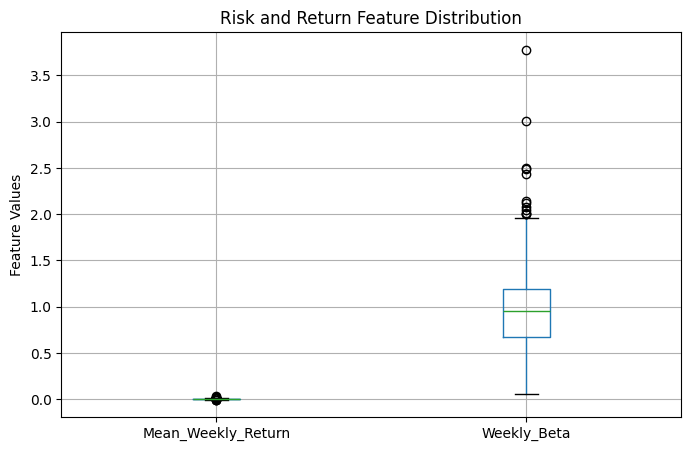

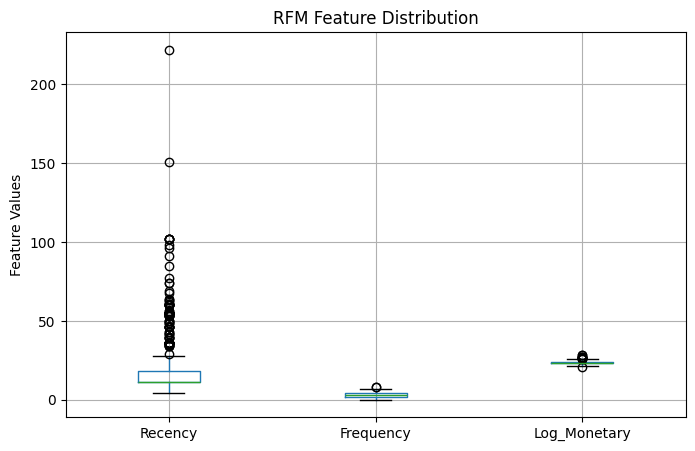

In [ ]:

# Calculate skewness before standardisation
print("Risk-return skewness:")
print(risk_return_matrix.skew())

print("\nRFM skewness:")
print(rfm_clustering.skew())

# Display boxplots to identify possible outliers
risk_return_matrix.boxplot(figsize=(8, 5))
plt.title('Risk and Return Feature Distribution')
plt.ylabel('Feature Values')
plt.show()

rfm_clustering.boxplot(figsize=(8, 5))
plt.title('RFM Feature Distribution')
plt.ylabel('Feature Values')
plt.show()


In [ ]:

# Standardise risk-return features
risk_scaler = StandardScaler()

risk_scaled = pd.DataFrame(
    risk_scaler.fit_transform(risk_return_matrix),
    columns=risk_return_matrix.columns,
    index=risk_return_matrix.index
)

# Standardise RFM features separately
rfm_scaler = StandardScaler()

rfm_scaled = pd.DataFrame(
    rfm_scaler.fit_transform(rfm_clustering),
    columns=rfm_clustering.columns,
    index=rfm_clustering.index
)

# Display the standardised feature matrices
print("Standardised Risk-Return Features:")
print(risk_scaled.head())

print("\nStandardised RFM Features:")
print(rfm_scaled.head())


Standardised Risk-Return Features:
        Mean_Weekly_Return  Weekly_Beta
Ticker                                 
MMM              -0.573259    -0.269702
AOS              -0.316315     0.137432
ABT              -0.625100    -0.938866
ABBV              0.216389    -1.309563
ACN              -0.199468     0.372946

Standardised RFM Features:
         Recency  Frequency  Log_Monetary
Ticker                                   
MMM    -0.448029   0.750960      0.307202
AOS    -0.448029  -0.757016     -1.488869
ABT    -0.448029  -1.511005      0.628558
ABBV   -0.448029  -0.003028      1.329130
ACN    -0.448029  -0.757016      1.039821


In [ ]:

# Check standardised feature means and standard deviations
print("Risk-return means:")
print(risk_scaled.mean())

print("\nRFM means:")
print(rfm_scaled.mean())

print("\nRisk-return standard deviations:")
print(risk_scaled.std(ddof=0))

print("\nRFM standard deviations:")
print(rfm_scaled.std(ddof=0))

# Save the prepared matrices
risk_scaled.to_csv('risk_return_scaled.csv')
rfm_scaled.to_csv('rfm_scaled.csv')

print("\nFeature preparation completed")


Risk-return means:
Mean_Weekly_Return    4.815425e-17
Weekly_Beta           6.777265e-17
dtype: float64

RFM means:
Recency        -1.783491e-17
Frequency      -4.102029e-17
Log_Monetary    1.373288e-15
dtype: float64

Risk-return standard deviations:
Mean_Weekly_Return    1.0
Weekly_Beta           1.0
dtype: float64

RFM standard deviations:
Recency         1.0
Frequency       1.0
Log_Monetary    1.0
dtype: float64

Feature preparation completed


In [ ]:

# 2.2 Agglomerative Clustering

# Import libraries for hierarchical clustering
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

# Import libraries for visualisation
import matplotlib.pyplot as plt
import pandas as pd


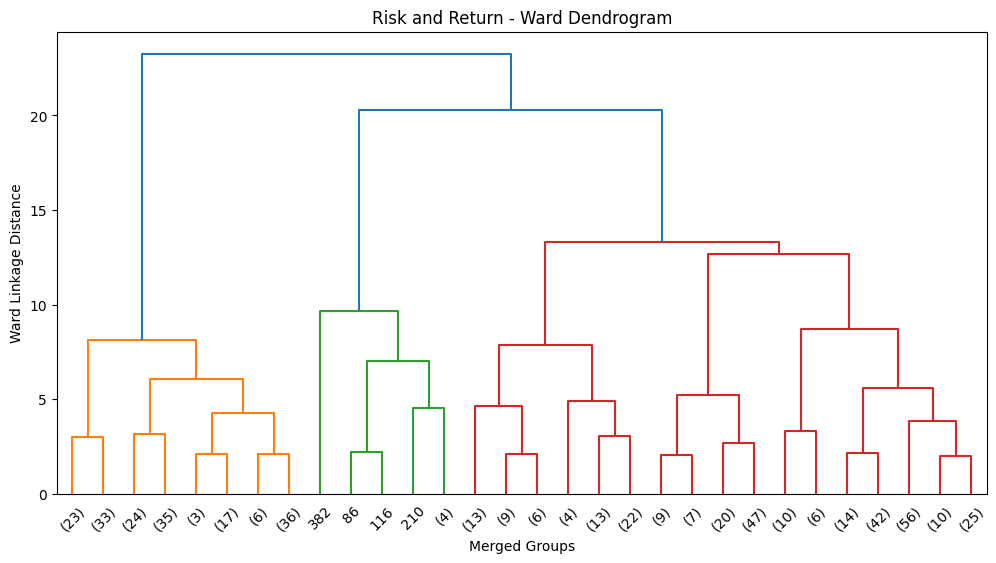

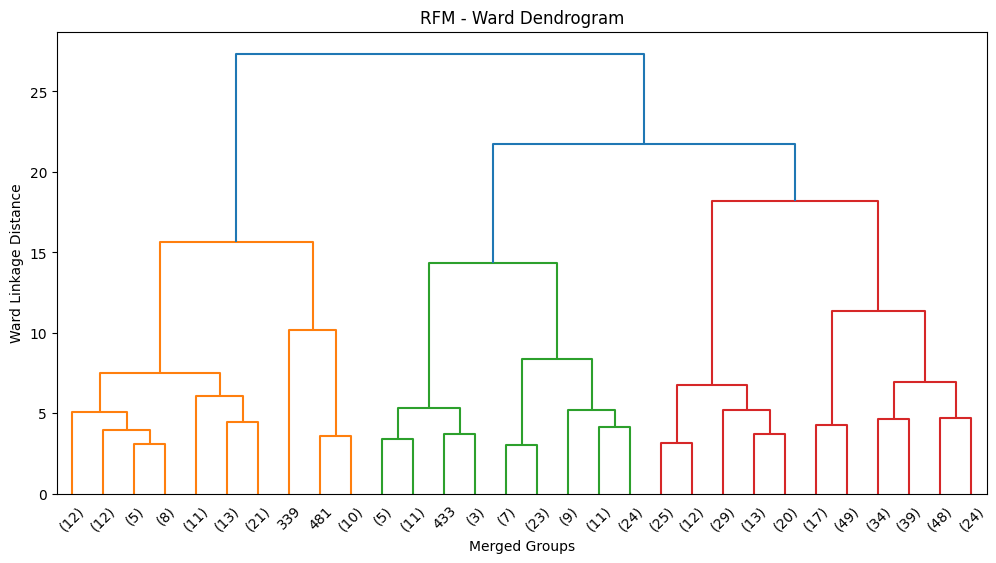

In [ ]:

# Apply Ward linkage using Euclidean distance
risk_linkage = linkage(
    risk_scaled,
    method='ward',
    metric='euclidean'
)

rfm_linkage = linkage(
    rfm_scaled,
    method='ward',
    metric='euclidean'
)

# Plot the risk-return dendrogram
plt.figure(figsize=(12, 6))

dendrogram(
    risk_linkage,
    truncate_mode='lastp',
    p=30
)

plt.title('Risk and Return - Ward Dendrogram')
plt.xlabel('Merged Groups')
plt.ylabel('Ward Linkage Distance')
plt.show()

# Plot the RFM dendrogram
plt.figure(figsize=(12, 6))

dendrogram(
    rfm_linkage,
    truncate_mode='lastp',
    p=30
)

plt.title('RFM - Ward Dendrogram')
plt.xlabel('Merged Groups')
plt.ylabel('Ward Linkage Distance')
plt.show()


In [ ]:

# Compare cluster counts from 2 to 8
risk_ward_results = []

for k in range(2, 9):

    # Apply Ward agglomerative clustering
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward',
        metric='euclidean'
    )

    # Fit the model and obtain cluster labels
    labels = model.fit_predict(risk_scaled)

    # Calculate the silhouette score
    score = silhouette_score(risk_scaled, labels)

    # Record the smallest and largest cluster sizes
    sizes = pd.Series(labels).value_counts()

    risk_ward_results.append({
        'Clusters': k,
        'Silhouette_Score': score,
        'Smallest_Cluster': sizes.min(),
        'Largest_Cluster': sizes.max()
    })

# Display the comparison results
risk_ward_results = pd.DataFrame(risk_ward_results)

print(risk_ward_results)


   Clusters  Silhouette_Score  Smallest_Cluster  Largest_Cluster
0         2          0.288845               177              321
1         3          0.320715                 8              313
2         4          0.297311                 8              246
3         5          0.288463                 8              177
4         6          0.289506                 1              177
5         7          0.296698                 1              177
6         8          0.279156                 1              147


In [ ]:

# Compare cluster counts from 2 to 8 for RFM
rfm_ward_results = []

for k in range(2, 9):

    # Apply Ward agglomerative clustering
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward',
        metric='euclidean'
    )

    # Fit the model and obtain cluster labels
    labels = model.fit_predict(rfm_scaled)

    # Calculate the silhouette score
    score = silhouette_score(rfm_scaled, labels)

    # Record cluster sizes
    sizes = pd.Series(labels).value_counts()

    rfm_ward_results.append({
        'Clusters': k,
        'Silhouette_Score': score,
        'Smallest_Cluster': sizes.min(),
        'Largest_Cluster': sizes.max()
    })

# Display the comparison results
rfm_ward_results = pd.DataFrame(rfm_ward_results)

print(rfm_ward_results)


   Clusters  Silhouette_Score  Smallest_Cluster  Largest_Cluster
0         2          0.358679                94              404
1         3          0.316000                94              310
2         4          0.287608                94              211
3         5          0.310284                12              211
4         6          0.318334                12              211
5         7          0.306113                12              145
6         8          0.307970                 1              145


In [ ]:

# Compare cluster counts from 2 to 8 for RFM
rfm_ward_results = []

for k in range(2, 9):

    # Apply Ward agglomerative clustering
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward',
        metric='euclidean'
    )

    # Fit the model and obtain cluster labels
    labels = model.fit_predict(rfm_scaled)

    # Calculate the silhouette score
    score = silhouette_score(rfm_scaled, labels)

    # Record cluster sizes
    sizes = pd.Series(labels).value_counts()

    rfm_ward_results.append({
        'Clusters': k,
        'Silhouette_Score': score,
        'Smallest_Cluster': sizes.min(),
        'Largest_Cluster': sizes.max()
    })

# Display the comparison results
rfm_ward_results = pd.DataFrame(rfm_ward_results)

print(rfm_ward_results)


   Clusters  Silhouette_Score  Smallest_Cluster  Largest_Cluster
0         2          0.358679                94              404
1         3          0.316000                94              310
2         4          0.287608                94              211
3         5          0.310284                12              211
4         6          0.318334                12              211
5         7          0.306113                12              145
6         8          0.307970                 1              145


In [ ]:

# Compare cluster counts from 2 to 8 for RFM
rfm_ward_results = []

for k in range(2, 9):

    # Apply Ward agglomerative clustering
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward',
        metric='euclidean'
    )

    # Fit the model and obtain cluster labels
    labels = model.fit_predict(rfm_scaled)

    # Calculate the silhouette score
    score = silhouette_score(rfm_scaled, labels)

    # Record cluster sizes
    sizes = pd.Series(labels).value_counts()

    rfm_ward_results.append({
        'Clusters': k,
        'Silhouette_Score': score,
        'Smallest_Cluster': sizes.min(),
        'Largest_Cluster': sizes.max()
    })

# Display the comparison results
rfm_ward_results = pd.DataFrame(rfm_ward_results)

print(rfm_ward_results)


   Clusters  Silhouette_Score  Smallest_Cluster  Largest_Cluster
0         2          0.358679                94              404
1         3          0.316000                94              310
2         4          0.287608                94              211
3         5          0.310284                12              211
4         6          0.318334                12              211
5         7          0.306113                12              145
6         8          0.307970                 1              145


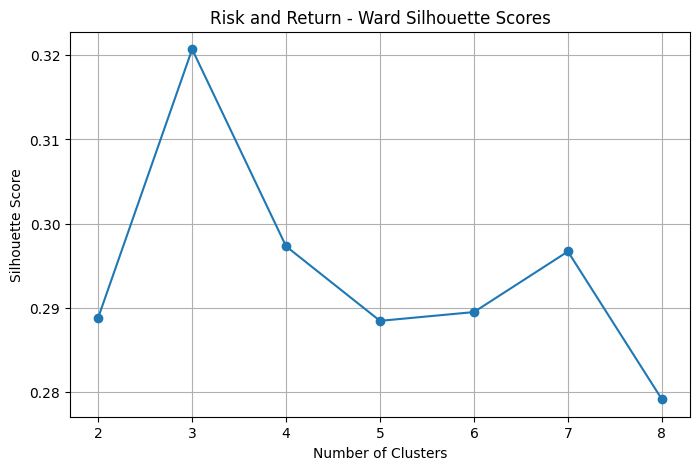

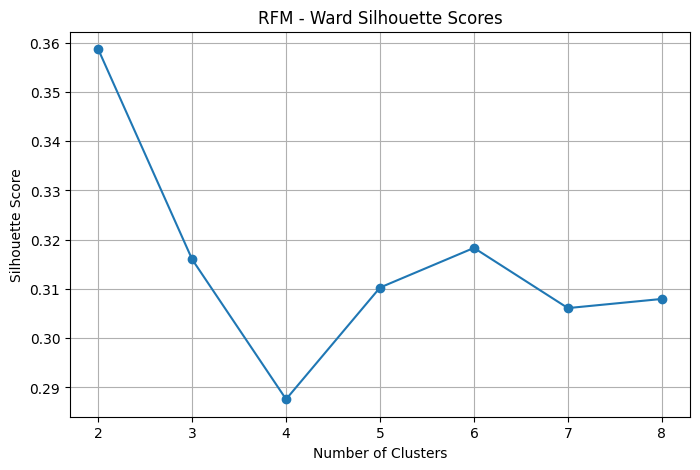

In [ ]:

# Plot silhouette scores for risk-return clustering
plt.figure(figsize=(8, 5))

plt.plot(
    risk_ward_results['Clusters'],
    risk_ward_results['Silhouette_Score'],
    marker='o'
)

plt.title('Risk and Return - Ward Silhouette Scores')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 9))
plt.grid(True)
plt.show()

# Plot silhouette scores for RFM clustering
plt.figure(figsize=(8, 5))

plt.plot(
    rfm_ward_results['Clusters'],
    rfm_ward_results['Silhouette_Score'],
    marker='o'
)

plt.title('RFM - Ward Silhouette Scores')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 9))
plt.grid(True)
plt.show()
*96

In [ ]:

# Examine cluster profiles for different cluster counts

for name, scaled_data, original_data in [
    ('Risk and Return', risk_scaled, risk_return_matrix),
    ('RFM', rfm_scaled, rfm_matrix)
]:

    print("\n", name)

    for k in range(2, 9):

        # Fit the Ward clustering model
        model = AgglomerativeClustering(
            n_clusters=k,
            linkage='ward',
            metric='euclidean'
        )

        labels = model.fit_predict(scaled_data)

        # Group the original feature values by cluster
        profiles = original_data.copy()
        profiles['Cluster'] = labels

        print("\nNumber of clusters:", k)
        print("Cluster sizes:")
        print(profiles['Cluster'].value_counts().sort_index())

        print("Cluster means:")
        print(profiles.groupby('Cluster').mean().round(3))



 Risk and Return

Number of clusters: 2
Cluster sizes:
Cluster
0    321
1    177
Name: count, dtype: int64
Cluster means:
         Mean_Weekly_Return  Weekly_Beta
Cluster                                 
0                     0.004        1.208
1                     0.002        0.579

Number of clusters: 3
Cluster sizes:
Cluster
0    313
1    177
2      8
Name: count, dtype: int64
Cluster means:
         Mean_Weekly_Return  Weekly_Beta
Cluster                                 
0                     0.003        1.178
1                     0.002        0.579
2                     0.017        2.369

Number of clusters: 4
Cluster sizes:
Cluster
0    246
1    177
2      8
3     67
Name: count, dtype: int64
Cluster means:
         Mean_Weekly_Return  Weekly_Beta
Cluster                                 
0                     0.003        1.060
1                     0.002        0.579
2                     0.017        2.369
3                     0.003        1.611

Number of clusters: 5
Cl

In [ ]:

# Save the cluster count comparison tables
risk_ward_results.to_csv(
    'risk_ward_comparison.csv',
    index=False
)

rfm_ward_results.to_csv(
    'rfm_ward_comparison.csv',
    index=False
)

print("Ward clustering comparison results saved successfully")


Ward clustering comparison results saved successfully


In [ ]:

# 2.2 Selected Ward Clustering Models

# Select 3 clusters for risk and return
risk_ward_model = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward',
    metric='euclidean'
)

risk_ward_labels = risk_ward_model.fit_predict(risk_scaled)

# Select 2 clusters for RFM
rfm_ward_model = AgglomerativeClustering(
    n_clusters=2,
    linkage='ward',
    metric='euclidean'
)

rfm_ward_labels = rfm_ward_model.fit_predict(rfm_scaled)

# Save the cluster assignments
ward_assignments = pd.DataFrame({
    'Ward_Risk_Return': risk_ward_labels,
    'Ward_RFM': rfm_ward_labels
}, index=risk_scaled.index)

print(ward_assignments.head())
print(ward_assignments.describe())

ward_assignments.to_csv('ward_cluster_assignments.csv')


        Ward_Risk_Return  Ward_RFM
Ticker                            
MMM                    0         0
AOS                    0         0
ABT                    1         0
ABBV                   1         0
ACN                    0         0
       Ward_Risk_Return    Ward_RFM
count         498.00000  498.000000
mean            0.38755    0.188755
std             0.51964    0.391707
min             0.00000    0.000000
25%             0.00000    0.000000
50%             0.00000    0.000000
75%             1.00000    0.000000
max             2.00000    1.000000


In [ ]:

# 2.2 Selected Ward Clustering Models

# Select 3 clusters for risk and return
risk_ward_model = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward',
    metric='euclidean'
)

risk_ward_labels = risk_ward_model.fit_predict(risk_scaled)

# Select 2 clusters for RFM
rfm_ward_model = AgglomerativeClustering(
    n_clusters=2,
    linkage='ward',
    metric='euclidean'
)

rfm_ward_labels = rfm_ward_model.fit_predict(rfm_scaled)

# Save the cluster assignments
ward_assignments = pd.DataFrame({
    'Ward_Risk_Return': risk_ward_labels,
    'Ward_RFM': rfm_ward_labels
}, index=risk_scaled.index)

print(ward_assignments.head())
print(ward_assignments.describe())

ward_assignments.to_csv('ward_cluster_assignments.csv')


        Ward_Risk_Return  Ward_RFM
Ticker                            
MMM                    0         0
AOS                    0         0
ABT                    1         0
ABBV                   1         0
ACN                    0         0
       Ward_Risk_Return    Ward_RFM
count         498.00000  498.000000
mean            0.38755    0.188755
std             0.51964    0.391707
min             0.00000    0.000000
25%             0.00000    0.000000
50%             0.00000    0.000000
75%             1.00000    0.000000
max             2.00000    1.000000


In [ ]:

# Calculate profiles using the original feature values

risk_ward_profiles = risk_return_matrix.copy()
risk_ward_profiles['Cluster'] = risk_ward_labels

rfm_ward_profiles = rfm_matrix.copy()
rfm_ward_profiles['Cluster'] = rfm_ward_labels

# Display the cluster sizes and mean feature values
print("Risk-Return Ward Cluster Profiles:")
print(risk_ward_profiles.groupby('Cluster').mean())
print(risk_ward_profiles['Cluster'].value_counts().sort_index())

print("\nRFM Ward Cluster Profiles:")
print(rfm_ward_profiles.groupby('Cluster').mean())
print(rfm_ward_profiles['Cluster'].value_counts().sort_index())

# Save the cluster profiles
risk_ward_profiles.groupby('Cluster').mean().to_csv(
    'risk_ward_profiles.csv'
)

rfm_ward_profiles.groupby('Cluster').mean().to_csv(
    'rfm_ward_profiles.csv'
)


Risk-Return Ward Cluster Profiles:
         Mean_Weekly_Return  Weekly_Beta
Cluster                                 
0                  0.003205     1.177963
1                  0.002084     0.578851
2                  0.017432     2.369210
Cluster
0    313
1    177
2      8
Name: count, dtype: int64

RFM Ward Cluster Profiles:
           Recency  Frequency      Monetary  Log_Monetary
Cluster                                                  
0        12.361386   3.220297  3.820898e+10     23.662823
1        55.531915   2.074468  4.565006e+10     23.808350
Cluster
0    404
1     94
Name: count, dtype: int64


In [ ]:

# 2.3 K-Means Clustering

# Import K-Means and evaluation method
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


In [ ]:

# Compare k values from 2 to 8
risk_kmeans_results = []

for k in range(2, 9):

    # Apply K-Means clustering
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Fit the model
    labels = model.fit_predict(risk_scaled)

    # Calculate silhouette score and inertia
    score = silhouette_score(risk_scaled, labels)
    inertia = model.inertia_

    # Check cluster sizes
    sizes = pd.Series(labels).value_counts()

    risk_kmeans_results.append({
        'Clusters': k,
        'Silhouette_Score': score,
        'Inertia': inertia,
        'Smallest_Cluster': sizes.min(),
        'Largest_Cluster': sizes.max()
    })

risk_kmeans_results = pd.DataFrame(risk_kmeans_results)

print(risk_kmeans_results)


   Clusters  Silhouette_Score     Inertia  Smallest_Cluster  Largest_Cluster
0         2          0.399826  659.460912               147              351
1         3          0.349059  498.124901                 9              281
2         4          0.336534  386.977274                 8              192
3         5          0.347689  318.952963                 7              189
4         6          0.351854  265.400010                 2              187
5         7          0.334708  232.317289                 1              159
6         8          0.328350  195.203277                 2              128


In [ ]:

# Compare k values from 2 to 8 for RFM
rfm_kmeans_results = []

for k in range(2, 9):

    # Apply K-Means clustering
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Fit the model
    labels = model.fit_predict(rfm_scaled)

    # Calculate silhouette score and inertia
    score = silhouette_score(rfm_scaled, labels)
    inertia = model.inertia_

    # Check cluster sizes
    sizes = pd.Series(labels).value_counts()

    rfm_kmeans_results.append({
        'Clusters': k,
        'Silhouette_Score': score,
        'Inertia': inertia,
        'Smallest_Cluster': sizes.min(),
        'Largest_Cluster': sizes.max()
    })

rfm_kmeans_results = pd.DataFrame(rfm_kmeans_results)

print(rfm_kmeans_results)


   Clusters  Silhouette_Score      Inertia  Smallest_Cluster  Largest_Cluster
0         2          0.418999  1094.049704                72              426
1         3          0.324209   818.263499                64              277
2         4          0.340464   625.212105                61              216
3         5          0.356812   528.698704                11              202
4         6          0.346036   447.513297                11              145
5         7          0.349236   396.282544                 1              146
6         8          0.342138   352.769610                 1              150


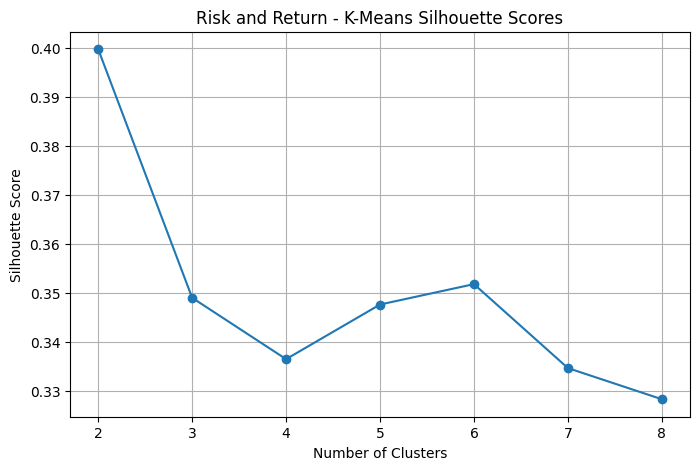

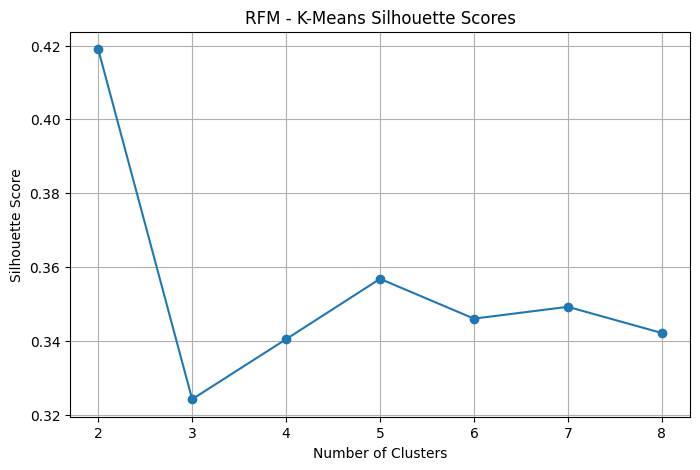

In [ ]:

# Plot K-Means silhouette scores for risk-return
plt.figure(figsize=(8, 5))

plt.plot(
    risk_kmeans_results['Clusters'],
    risk_kmeans_results['Silhouette_Score'],
    marker='o'
)

plt.title('Risk and Return - K-Means Silhouette Scores')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 9))
plt.grid(True)
plt.show()

# Plot K-Means silhouette scores for RFM
plt.figure(figsize=(8, 5))

plt.plot(
    rfm_kmeans_results['Clusters'],
    rfm_kmeans_results['Silhouette_Score'],
    marker='o'
)

plt.title('RFM - K-Means Silhouette Scores')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 9))
plt.grid(True)
plt.show()


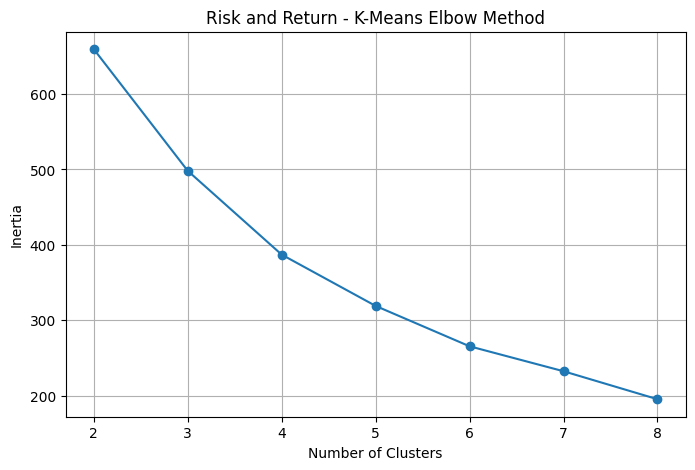

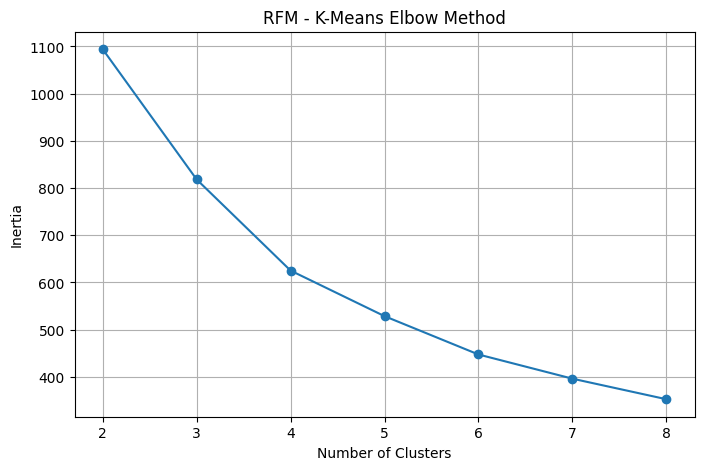

In [ ]:

# Plot inertia values for risk-return
plt.figure(figsize=(8, 5))

plt.plot(
    risk_kmeans_results['Clusters'],
    risk_kmeans_results['Inertia'],
    marker='o'
)

plt.title('Risk and Return - K-Means Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.xticks(range(2, 9))
plt.grid(True)
plt.show()

# Plot inertia values for RFM
plt.figure(figsize=(8, 5))

plt.plot(
    rfm_kmeans_results['Clusters'],
    rfm_kmeans_results['Inertia'],
    marker='o'
)

plt.title('RFM - K-Means Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.xticks(range(2, 9))
plt.grid(True)
plt.show()


In [ ]:

# Compare cluster profiles using original feature values

for name, scaled_data, original_data in [
    ('Risk and Return', risk_scaled, risk_return_matrix),
    ('RFM', rfm_scaled, rfm_matrix)
]:

    print("\n", name)

    for k in range(2, 9):

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        labels = model.fit_predict(scaled_data)

        # Calculate cluster sizes and average feature values
        profiles = original_data.copy()
        profiles['Cluster'] = labels

        print("\nNumber of clusters:", k)
        print("Cluster sizes:")
        print(profiles['Cluster'].value_counts().sort_index())

        print("Cluster means:")
        print(profiles.groupby('Cluster').mean().round(3))



 Risk and Return

Number of clusters: 2
Cluster sizes:
Cluster
0    351
1    147
Name: count, dtype: int64
Cluster means:
         Mean_Weekly_Return  Weekly_Beta
Cluster                                 
0                     0.002        0.799
1                     0.005        1.427

Number of clusters: 3
Cluster sizes:
Cluster
0    208
1    281
2      9
Name: count, dtype: int64
Cluster means:
         Mean_Weekly_Return  Weekly_Beta
Cluster                                 
0                     0.004        1.288
1                     0.002        0.716
2                     0.017        2.329

Number of clusters: 4
Cluster sizes:
Cluster
0    177
1    121
2      8
3    192
Name: count, dtype: int64
Cluster means:
         Mean_Weekly_Return  Weekly_Beta
Cluster                                 
0                     0.001        1.123
1                     0.006        1.291
2                     0.017        2.369
3                     0.003        0.605

Number of clusters: 5
Cl

In [ ]:

# Save the comparison tables
risk_kmeans_results.to_csv(
    'risk_kmeans_comparison.csv',
    index=False
)

rfm_kmeans_results.to_csv(
    'rfm_kmeans_comparison.csv',
    index=False
)

print("K-Means comparison results saved successfully")


K-Means comparison results saved successfully


In [ ]:

# 2.4 Cluster Profiles and Algorithm Comparison

# Apply K-Means with 2 clusters for risk and return
risk_kmeans_model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

risk_kmeans_labels = risk_kmeans_model.fit_predict(risk_scaled)

# Apply K-Means with 2 clusters for RFM
rfm_kmeans_model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

rfm_kmeans_labels = rfm_kmeans_model.fit_predict(rfm_scaled)

# Check the cluster sizes
print("Risk-Return K-Means:")
print(pd.Series(risk_kmeans_labels).value_counts().sort_index())

print("\nRFM K-Means:")
print(pd.Series(rfm_kmeans_labels).value_counts().sort_index())


Risk-Return K-Means:
0    351
1    147
Name: count, dtype: int64

RFM K-Means:
0     72
1    426
Name: count, dtype: int64


In [ ]:

# Combine Ward and K-Means cluster assignments
cluster_assignments = pd.DataFrame({
    'Ward_Risk_Return': risk_ward_labels,
    'KMeans_Risk_Return': risk_kmeans_labels,
    'Ward_RFM': rfm_ward_labels,
    'KMeans_RFM': rfm_kmeans_labels
}, index=combined_features.index)

# Display the cluster assignments
print(cluster_assignments.head(10))

# Save the four clustering solutions
cluster_assignments.to_csv('all_cluster_assignments.csv')

print("Cluster assignments saved successfully")


        Ward_Risk_Return  KMeans_Risk_Return  Ward_RFM  KMeans_RFM
Ticker                                                            
MMM                    0                   0         0           1
AOS                    0                   0         0           1
ABT                    1                   0         0           1
ABBV                   1                   0         0           1
ACN                    0                   0         0           1
ADBE                   0                   1         0           1
AMD                    0                   1         0           1
AES                    0                   0         1           0
AFL                    1                   0         0           1
A                      0                   0         0           1
Cluster assignments saved successfully


In [ ]:

# Calculate cluster profiles for all four solutions
for column in cluster_assignments.columns:

    # Combine original features with cluster labels
    profiles = combined_features.copy()
    profiles['Cluster'] = cluster_assignments[column]

    # Calculate the average values for each cluster
    cluster_means = profiles.groupby('Cluster').mean()

    # Calculate the number of shares in each cluster
    cluster_sizes = profiles.groupby('Cluster').size()

    print("\n", column)
    print("Cluster sizes:")
    print(cluster_sizes)

    print("Cluster profiles:")
    print(cluster_means)

    # Save the cluster profile
    cluster_means.to_csv(column + '_profiles.csv')



 Ward_Risk_Return
Cluster sizes:
Cluster
0    313
1    177
2      8
dtype: int64
Cluster profiles:
         Mean_Weekly_Return  Weekly_Beta    Recency  Frequency      Monetary
Cluster                                                                     
0                  0.003205     1.177963  19.169329   3.028754  4.197537e+10
1                  0.002084     0.578851  21.305085   2.943503  2.311690e+10
2                  0.017432     2.369210  55.375000   3.375000  3.121938e+11

 KMeans_Risk_Return
Cluster sizes:
Cluster
0    351
1    147
dtype: int64
Cluster profiles:
         Mean_Weekly_Return  Weekly_Beta    Recency  Frequency      Monetary
Cluster                                                                     
0                  0.002024     0.798552  19.148148   2.923077  2.229362e+10
1                  0.005449     1.427354  23.761905   3.197279  8.096921e+10

 Ward_RFM
Cluster sizes:
Cluster
0    404
1     94
dtype: int64
Cluster profiles:
         Mean_Weekly_Return  We

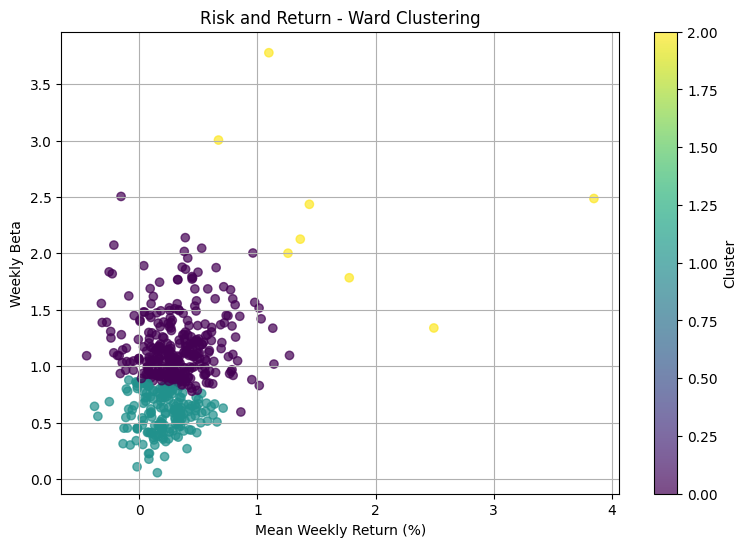

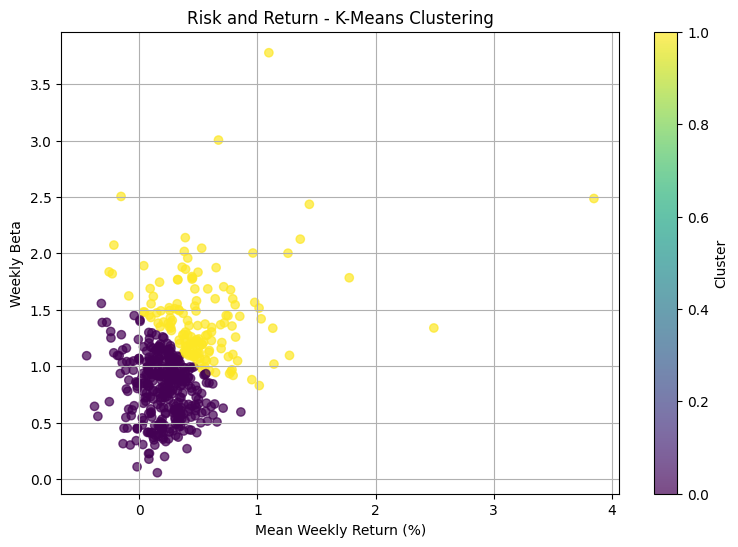

In [ ]:

# Visualise the Ward risk-return clusters
plt.figure(figsize=(9, 6))

plt.scatter(
    risk_return_matrix['Mean_Weekly_Return'] * 100,
    risk_return_matrix['Weekly_Beta'],
    c=risk_ward_labels,
    cmap='viridis',
    alpha=0.7
)

plt.title('Risk and Return - Ward Clustering')
plt.xlabel('Mean Weekly Return (%)')
plt.ylabel('Weekly Beta')
plt.colorbar(label='Cluster')
plt.grid(True)
plt.show()

# Visualise the K-Means risk-return clusters
plt.figure(figsize=(9, 6))

plt.scatter(
    risk_return_matrix['Mean_Weekly_Return'] * 100,
    risk_return_matrix['Weekly_Beta'],
    c=risk_kmeans_labels,
    cmap='viridis',
    alpha=0.7
)

plt.title('Risk and Return - K-Means Clustering')
plt.xlabel('Mean Weekly Return (%)')
plt.ylabel('Weekly Beta')
plt.colorbar(label='Cluster')
plt.grid(True)
plt.show()


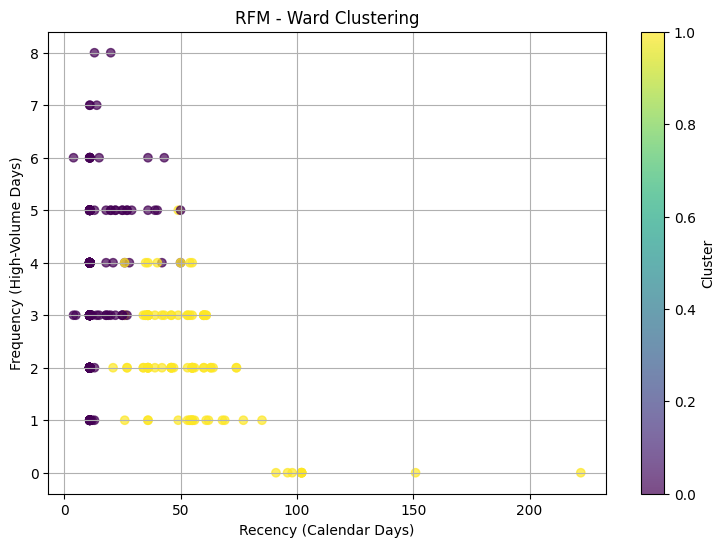

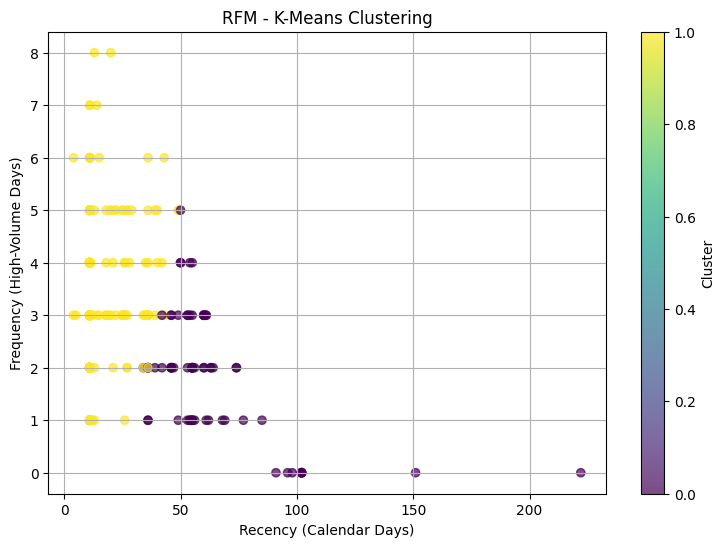

In [ ]:

# Visualise Ward RFM clusters using Recency and Frequency
plt.figure(figsize=(9, 6))

plt.scatter(
    rfm_matrix['Recency'],
    rfm_matrix['Frequency'],
    c=rfm_ward_labels,
    cmap='viridis',
    alpha=0.7
)

plt.title('RFM - Ward Clustering')
plt.xlabel('Recency (Calendar Days)')
plt.ylabel('Frequency (High-Volume Days)')
plt.colorbar(label='Cluster')
plt.grid(True)
plt.show()

# Visualise K-Means RFM clusters
plt.figure(figsize=(9, 6))

plt.scatter(
    rfm_matrix['Recency'],
    rfm_matrix['Frequency'],
    c=rfm_kmeans_labels,
    cmap='viridis',
    alpha=0.7
)

plt.title('RFM - K-Means Clustering')
plt.xlabel('Recency (Calendar Days)')
plt.ylabel('Frequency (High-Volume Days)')
plt.colorbar(label='Cluster')
plt.grid(True)
plt.show()


In [ ]:

# Compare risk-return cluster assignments
risk_comparison = pd.crosstab(
    cluster_assignments['Ward_Risk_Return'],
    cluster_assignments['KMeans_Risk_Return']
)

print("Risk-Return Ward vs K-Means:")
print(risk_comparison)

# Compare RFM cluster assignments
rfm_comparison = pd.crosstab(
    cluster_assignments['Ward_RFM'],
    cluster_assignments['KMeans_RFM']
)

print("\nRFM Ward vs K-Means:")
print(rfm_comparison)

# Save the comparison tables
risk_comparison.to_csv('risk_algorithm_comparison.csv')
rfm_comparison.to_csv('rfm_algorithm_comparison.csv')


Risk-Return Ward vs K-Means:
KMeans_Risk_Return    0    1
Ward_Risk_Return            
0                   174  139
1                   177    0
2                     0    8

RFM Ward vs K-Means:
KMeans_RFM   0    1
Ward_RFM           
0            2  402
1           70   24


In [ ]:

# Compare silhouette scores of the selected solutions
final_comparison = pd.DataFrame({
    'Analysis': [
        'Risk-Return', 'Risk-Return',
        'RFM', 'RFM'
    ],
    'Algorithm': [
        'Ward', 'K-Means',
        'Ward', 'K-Means'
    ],
    'Clusters': [3, 2, 2, 2],
    'Silhouette_Score': [
        silhouette_score(risk_scaled, risk_ward_labels),
        silhouette_score(risk_scaled, risk_kmeans_labels),
        silhouette_score(rfm_scaled, rfm_ward_labels),
        silhouette_score(rfm_scaled, rfm_kmeans_labels)
    ]
})

print(final_comparison)

# Save the final algorithm comparison
final_comparison.to_csv(
    'final_algorithm_comparison.csv',
    index=False
)


      Analysis Algorithm  Clusters  Silhouette_Score
0  Risk-Return      Ward         3          0.320715
1  Risk-Return   K-Means         2          0.399826
2          RFM      Ward         2          0.358679
3          RFM   K-Means         2          0.418999


In [ ]:

# 2.5.1 Correlation Analysis

# Calculate correlations between R, F and log-transformed M
rfm_correlation = rfm_clustering[
    ['Recency', 'Frequency', 'Log_Monetary']
].corr()

# Display the correlation matrix
print("RFM Correlation Matrix:")
print(rfm_correlation.round(4))

# Save the correlation matrix
rfm_correlation.to_csv('rfm_correlation_matrix.csv')


RFM Correlation Matrix:
              Recency  Frequency  Log_Monetary
Recency        1.0000    -0.3402        0.1647
Frequency     -0.3402     1.0000        0.0219
Log_Monetary   0.1647     0.0219        1.0000


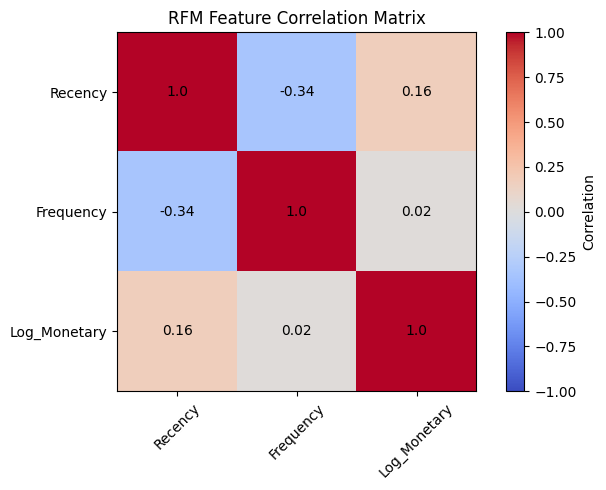

In [ ]:

# Plot the correlation matrix
plt.figure(figsize=(7, 5))

plt.imshow(
    rfm_correlation,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

# Add feature labels
plt.xticks(
    range(3),
    rfm_correlation.columns,
    rotation=45
)

plt.yticks(
    range(3),
    rfm_correlation.index
)

# Display correlation values inside the plot
for i in range(3):
    for j in range(3):
        plt.text(
            j, i,
            round(rfm_correlation.iloc[i, j], 2),
            ha='center',
            va='center'
        )

plt.colorbar(label='Correlation')
plt.title('RFM Feature Correlation Matrix')
plt.tight_layout()
plt.show()


In [ ]:

# Display individual correlation values
print("Recency and Frequency:",
      rfm_correlation.loc['Recency', 'Frequency'])

print("Recency and Log Monetary:",
      rfm_correlation.loc['Recency', 'Log_Monetary'])

print("Frequency and Log Monetary:",
      rfm_correlation.loc['Frequency', 'Log_Monetary'])


Recency and Frequency: -0.3402354592193291
Recency and Log Monetary: 0.1646729710394336
Frequency and Log Monetary: 0.021868255576113136


In [ ]:

# 2.5.2 Removal of Monetary

# Select only Recency and Frequency
rf_matrix = rfm_clustering[
    ['Recency', 'Frequency']
].copy()

# Standardise the two features again
rf_scaler = StandardScaler()

rf_scaled = pd.DataFrame(
    rf_scaler.fit_transform(rf_matrix),
    columns=rf_matrix.columns,
    index=rf_matrix.index
)

# Check the prepared matrix
print(rf_scaled.head())
print("RF matrix shape:", rf_scaled.shape)


         Recency  Frequency
Ticker                     
MMM    -0.448029   0.750960
AOS    -0.448029  -0.757016
ABT    -0.448029  -1.511005
ABBV   -0.448029  -0.003028
ACN    -0.448029  -0.757016
RF matrix shape: (498, 2)


In [ ]:

# Apply Ward clustering without Monetary
# Use the same k = 2 as the selected Ward RFM model

rf_ward_model = AgglomerativeClustering(
    n_clusters=2,
    linkage='ward',
    metric='euclidean'
)

rf_ward_labels = rf_ward_model.fit_predict(rf_scaled)

# Check the new cluster sizes
print("Ward clustering without Monetary:")
print(pd.Series(rf_ward_labels).value_counts().sort_index())


Ward clustering without Monetary:
0    405
1     93
Name: count, dtype: int64


In [ ]:

# Import Adjusted Rand Index
from sklearn.metrics import adjusted_rand_score

# Compare the original RFM model with the RF-only model
ari_score = adjusted_rand_score(
    rfm_ward_labels,
    rf_ward_labels
)

print("Adjusted Rand Index:", ari_score)


Adjusted Rand Index: 0.9530695498615949


In [ ]:

# Create a comparison between original RFM and RF-only clusters
rf_membership_comparison = pd.crosstab(
    pd.Series(rfm_ward_labels, name='RFM_Cluster'),
    pd.Series(rf_ward_labels, name='RF_Cluster')
)

print("RFM vs RF Cluster Memberships:")
print(rf_membership_comparison)

# Save the comparison
rf_membership_comparison.to_csv(
    'rf_membership_comparison.csv'
)


RFM vs RF Cluster Memberships:
RF_Cluster     0   1
RFM_Cluster         
0            402   2
1              3  91


In [ ]:

# Compare Monetary values after removing Monetary from clustering

# Create a dataframe with the original Monetary values
monetary_comparison = pd.DataFrame({
    'Monetary': combined_features['Monetary'],
    'RFM_Cluster': rfm_ward_labels,
    'RF_Cluster': rf_ward_labels
}, index=combined_features.index)

# Calculate average Monetary for the original clusters
print("Original RFM cluster Monetary:")
print(
    monetary_comparison.groupby('RFM_Cluster')['Monetary'].mean()
)

# Calculate average Monetary for the reduced clusters
print("\nRF-only cluster Monetary:")
print(
    monetary_comparison.groupby('RF_Cluster')['Monetary'].mean()
)


Original RFM cluster Monetary:
RFM_Cluster
0    3.820898e+10
1    4.565006e+10
Name: Monetary, dtype: float64

RF-only cluster Monetary:
RF_Cluster
0    3.768854e+10
1    4.799647e+10
Name: Monetary, dtype: float64


In [ ]:

# Save the reduced cluster assignments
sensitivity_results = combined_features.copy()

sensitivity_results['Ward_RFM'] = rfm_ward_labels
sensitivity_results['Ward_RF_Only'] = rf_ward_labels

sensitivity_results.to_csv(
    'rfm_monetary_sensitivity.csv'
)

# Save the ARI result
ari_results = pd.DataFrame({
    'Comparison': ['Ward RFM vs Ward RF'],
    'Adjusted_Rand_Index': [ari_score]
})

ari_results.to_csv(
    'rfm_adjusted_rand_index.csv',
    index=False
)

print("RFM sensitivity results saved successfully")


RFM sensitivity results saved successfully


In [ ]:

# Task 3: Business Intelligence Interpretation
# 3.2.1 Cluster Profiles and Sector Composition

# Extract company ticker and sector details
sector_data = sp500_df[
    ['Symbol', 'GICS Sector']
].copy()

# Match ticker symbols with Yahoo Finance format
sector_data['Symbol'] = sector_data['Symbol'].str.replace(
    '.', '-', regex=False
)

# Use the ticker as the index
sector_data = sector_data.set_index('Symbol')

# Combine company sectors with cluster assignments
sector_clusters = cluster_assignments.join(
    sector_data['GICS Sector']
)

# Check the combined results
print(sector_clusters.head())

print("Shares without sector information:",
      sector_clusters['GICS Sector'].isna().sum())


        Ward_Risk_Return  KMeans_Risk_Return  Ward_RFM  KMeans_RFM  \
Ticker                                                               
MMM                    0                   0         0           1   
AOS                    0                   0         0           1   
ABT                    1                   0         0           1   
ABBV                   1                   0         0           1   
ACN                    0                   0         0           1   

                   GICS Sector  
Ticker                          
MMM                Industrials  
AOS                Industrials  
ABT                Health Care  
ABBV               Health Care  
ACN     Information Technology  
Shares without sector information: 0


In [ ]:

# Calculate the sector composition of each clustering solution

for column in cluster_assignments.columns:

    # Count shares in each sector and cluster
    sector_counts = pd.crosstab(
        sector_clusters[column],
        sector_clusters['GICS Sector']
    )

    # Convert counts into percentages within each cluster
    sector_percentages = pd.crosstab(
        sector_clusters[column],
        sector_clusters['GICS Sector'],
        normalize='index'
    ) * 100

    print("\n", column)
    print("Sector counts:")
    print(sector_counts)

    print("\nSector percentages:")
    print(sector_percentages.round(2))

    # Save the sector composition
    sector_counts.to_csv(column + '_sector_counts.csv')
    sector_percentages.to_csv(
        column + '_sector_percentages.csv'
    )



 Ward_Risk_Return
Sector counts:
GICS Sector       Communication Services  Consumer Discretionary  \
Ward_Risk_Return                                                   
0                                     11                      39   
1                                      9                       7   
2                                      2                       1   

GICS Sector       Consumer Staples  Energy  Financials  Health Care  \
Ward_Risk_Return                                                      
0                                4      11          52           29   
1                               28      10          23           31   
2                                0       0           1            0   

GICS Sector       Industrials  Information Technology  Materials  Real Estate  \
Ward_Risk_Return                                                                
0                          61                      68         15           19   
1                         

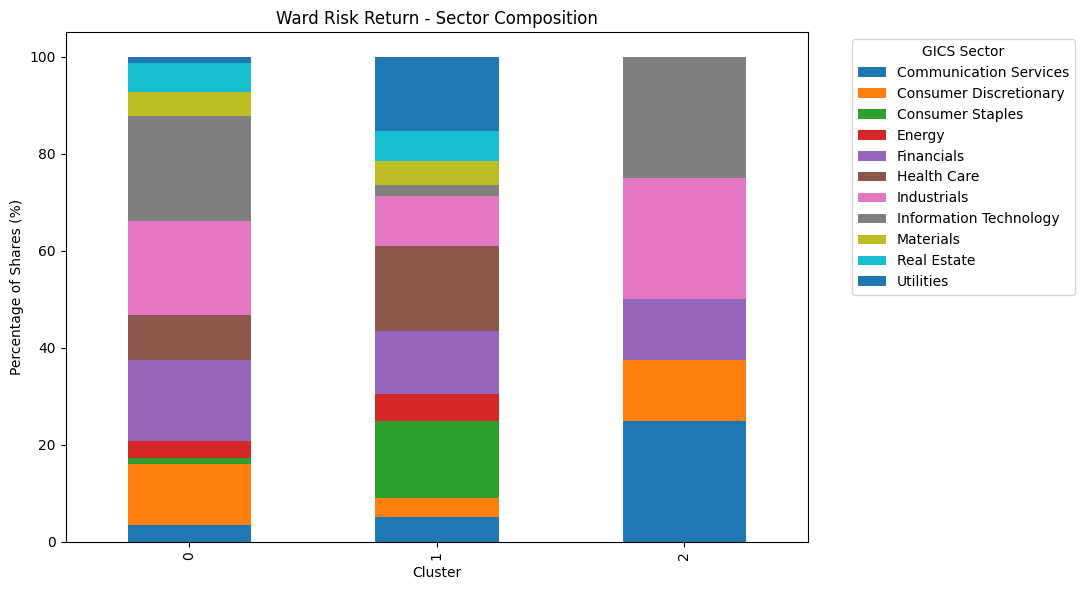

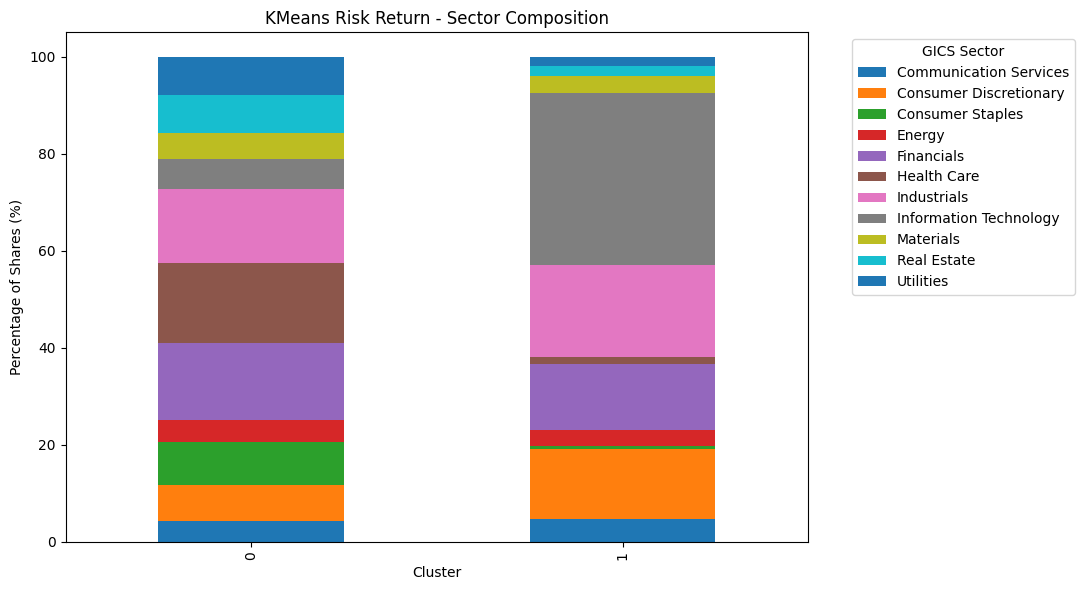

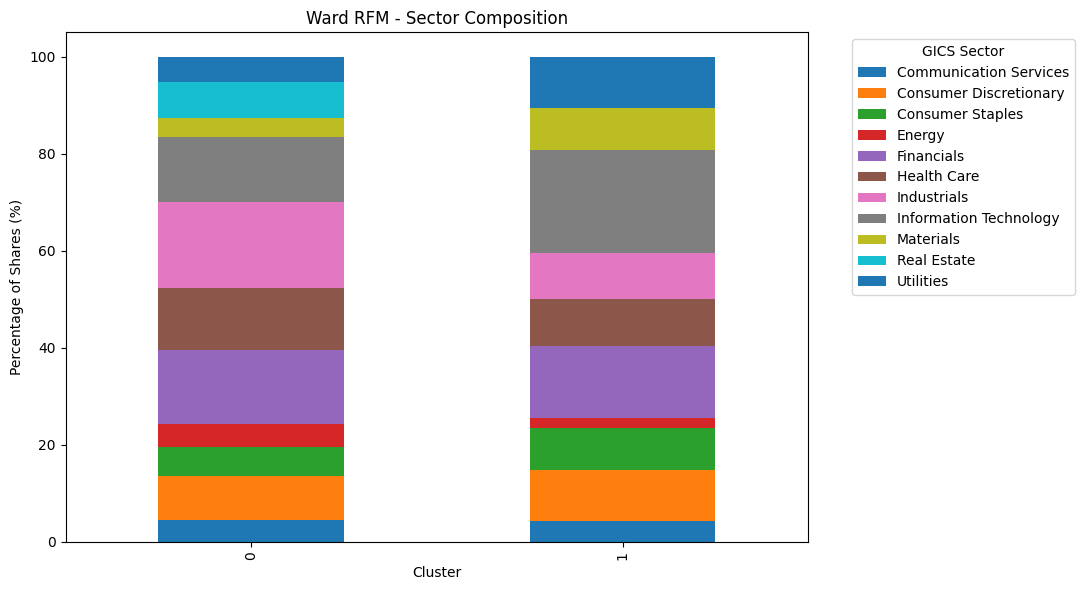

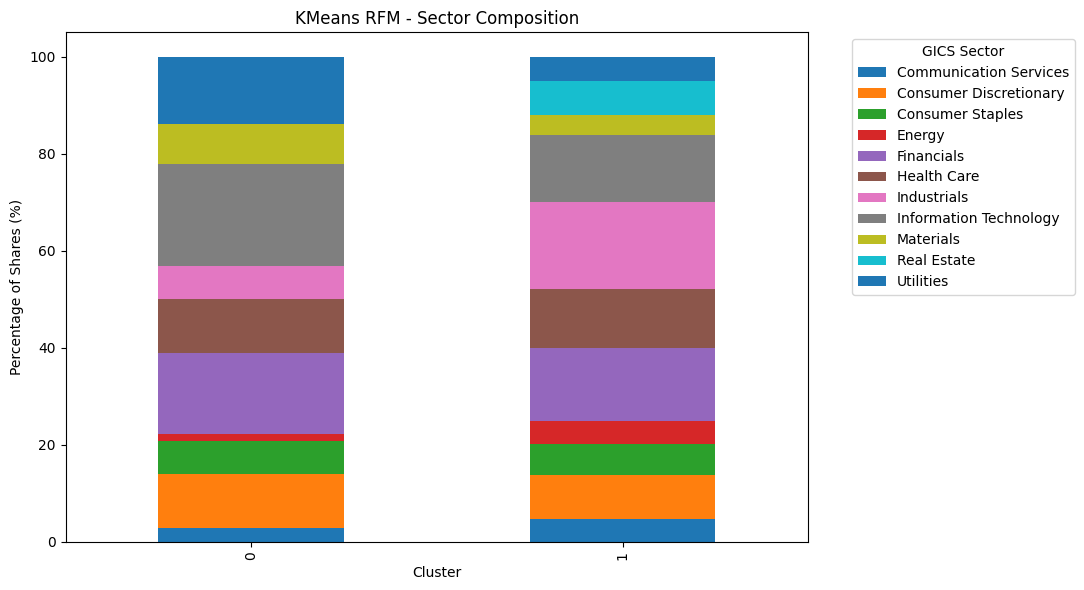

In [ ]:

# Plot the sector composition of each clustering solution

for column in cluster_assignments.columns:

    sector_percentages = pd.crosstab(
        sector_clusters[column],
        sector_clusters['GICS Sector'],
        normalize='index'
    ) * 100

    # Create a stacked bar chart
    sector_percentages.plot(
        kind='bar',
        stacked=True,
        figsize=(11, 6)
    )

    plt.title(column.replace('_', ' ') + ' - Sector Composition')
    plt.xlabel('Cluster')
    plt.ylabel('Percentage of Shares (%)')
    plt.legend(
        title='GICS Sector',
        bbox_to_anchor=(1.05, 1),
        loc='upper left'
    )
    plt.tight_layout()
    plt.show()


In [ ]:

# 3.2.2 Compare Risk-Return and Trading Activity Groups

# Compare Ward risk-return and Ward RFM groups
ward_group_comparison = pd.crosstab(
    cluster_assignments['Ward_Risk_Return'],
    cluster_assignments['Ward_RFM']
)

print("Ward Risk-Return vs Ward RFM:")
print(ward_group_comparison)

# Compare K-Means risk-return and K-Means RFM groups
kmeans_group_comparison = pd.crosstab(
    cluster_assignments['KMeans_Risk_Return'],
    cluster_assignments['KMeans_RFM']
)

print("\nK-Means Risk-Return vs K-Means RFM:")
print(kmeans_group_comparison)

# Save the comparisons
ward_group_comparison.to_csv(
    'ward_risk_vs_rfm.csv'
)

kmeans_group_comparison.to_csv(
    'kmeans_risk_vs_rfm.csv'
)


Ward Risk-Return vs Ward RFM:
Ward_RFM            0   1
Ward_Risk_Return         
0                 257  56
1                 142  35
2                   5   3

K-Means Risk-Return vs K-Means RFM:
KMeans_RFM           0    1
KMeans_Risk_Return         
0                   46  305
1                   26  121


In [ ]:

# 3.2.3 Data Limitations and Outliers

# Check shares with the highest Recency
print("Highest Recency:")
print(
    combined_features.sort_values(
        'Recency', ascending=False
    ).head(10)
)

# Check shares with the highest Monetary
print("\nHighest Monetary:")
print(
    combined_features.sort_values(
        'Monetary', ascending=False
    ).head(10)
)

# Check shares with the highest weekly beta
print("\nHighest Weekly Beta:")
print(
    combined_features.sort_values(
        'Weekly_Beta', ascending=False
    ).head(10)
)


Highest Recency:
        Mean_Weekly_Return  Weekly_Beta  Recency  Frequency      Monetary
Ticker                                                                   
NVDA              0.013624     2.125953    222.0          0  1.825337e+12
WEC               0.001375     0.384708    151.0          0  1.081689e+10
HRL              -0.000779     0.301090    102.0          0  4.373583e+09
MDT              -0.000909     0.618923    102.0          0  3.015812e+10
CB                0.003508     0.573060    102.0          0  2.523472e+10
COR               0.004373     0.548115    102.0          0  1.759981e+10
DUK               0.002005     0.353150    102.0          0  2.274797e+10
AZO               0.005274     0.758424     98.0          0  2.482392e+10
FCX               0.003368     1.492186     96.0          0  2.847770e+10
MKC              -0.000156     0.449063     91.0          0  7.850361e+09

Highest Monetary:
        Mean_Weekly_Return  Weekly_Beta  Recency  Frequency      Monetary
Ti